# TRƯỜNG ĐẠI HỌC KHOA HỌC TỰ NHIÊN - ĐHQGHN
## KHOA TOÁN - CƠ - TIN HỌC | BỘ MÔN TIN HỌC
### MÔN HỌC: MAT3562 - THỊ GIÁC MÁY TÍNH (COMPUTER VISION)

---
# BÀI THỰC HÀNH LAB 06: ĐỐI SÁNH HISTOGRAM VÀ HISTOGRAM BACKPROJECTION

**Học viên / Sinh viên thực hiện:** Đạt (datbritget)  
**Mục tiêu bài thực hành:**
1. **Bài 1:** Thực hiện quy trình tra cứu ảnh trên thư mục ảnh $D$ (`thu_muc_anh`) với ảnh truy vấn $Q$ (`ava.jpg`):
   - Thử nghiệm với các lựa chọn khác nhau của giá trị $k$, cấu hình histogram (số bin, không gian màu) và 4 phương pháp đối sánh (Correlation, Chi-Square, Intersection, Bhattacharyya).
   - **Bước 1:** Đối sánh trên ảnh xám (Grayscale).
   - **Bước 2:** Đối sánh trên ảnh màu (Color) với các cấu hình đa chiều (2D HSV, 3D RGB, ghép 3 kênh).
2. **Bài 2:** Phân đoạn bàn tay bằng kỹ thuật Histogram Backprojection kết hợp phân ngưỡng:
   - Học phân bố màu da từ vùng mẫu da tay (Skin ROI) trên không gian màu HSV.
   - Chiếu ngược Histogram Backprojection để tạo bản đồ xác suất (Probability Map).
   - Phân ngưỡng (Thresholding) và xử lý hình thái học (Morphology) để tách trọn vẹn bàn tay khỏi nền.
   - Hỗ trợ xử lý trên ảnh tĩnh `bantay.jpeg`, file video và luồng Webcam thời gian thực.
3. **Quy tắc bắt buộc:** Tất cả các histogram sau khi tính đều được **chuẩn hóa** bằng cách chia các giá trị cho số điểm ảnh của ảnh:
$$\bar{H}[k] = \frac{H[k]}{\text{Height} \times \text{Width}}$$
đảm bảo tổng các giá trị histogram bằng 1.0 và kết quả đối sánh không bị ảnh hưởng bởi độ phân giải của các ảnh.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
import math
import time
import warnings
warnings.filterwarnings('ignore')

# Cấu hình matplotlib
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

def cv2_imshow_safe(img, title=None, cmap=None):
    # Hàm hiển thị ảnh an toàn, tương thích cả Colab và Jupyter/VS Code
    plt.figure(figsize=(6, 6))
    if len(img.shape) == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap=cmap if cmap else 'gray')
    if title:
        plt.title(title, fontsize=12, fontweight='bold')
    plt.axis('off')
    plt.show()

print("OpenCV version:", cv2.__version__)
print("NumPy version :", np.__version__)
print("Thư mục làm việc hiện tại:", os.getcwd())
print("Môi trường và các thư viện hỗ trợ đã sẵn sàng!")

OpenCV version: 4.13.0

NumPy version : 2.2.6

Thư mục làm việc hiện tại: /home/datbritget/Documents/hocky-1-nam4-toantin/MAT3562-Thị giác máy tính/practice/lab06

Môi trường và các thư viện hỗ trợ đã sẵn sàng!



## 1. Cơ sở lý thuyết: Tính Histogram và Chuẩn hóa

### 1.1. Khái niệm Histogram
- **Histogram mức xám** là đồ thị thống kê số lượng điểm ảnh (pixel) xuất hiện tương ứng với mỗi mức xám (hoặc khoảng mức xám) trong ảnh.
- Khi chia dải mức xám $[0, 255]$ thành $n$ khoảng (bins), bước nhảy khoảng là $t = \frac{256}{n}$. Khoảng thứ $k$ ($0 \le k < n$) sẽ bao gồm các mức xám từ $[\lceil t \cdot k \rceil, \lceil t \cdot (k+1) \rceil - 1]$.

### 1.2. Chuẩn hóa Histogram (Normalization) - Yêu cầu cốt lõi
- **Tại sao cần chuẩn hóa?** Trong thực tế, các bức ảnh có thể có kích thước (chiều cao $\times$ chiều rộng) hoàn toàn khác nhau. Nếu chỉ dùng số đếm pixel thô, một bức ảnh lớn sẽ luôn có giá trị histogram vượt trội so với ảnh nhỏ, làm sai lệch hoàn toàn quá trình đối sánh độ tương đồng.
- **Công thức chuẩn hóa:** Chia mỗi giá trị trong histogram cho tổng số điểm ảnh của ảnh:
$$\bar{H}[k] = \frac{H[k]}{H_{img} \times W_{img}}$$
Khi đó:
$$\sum_{k=0}^{n-1} \bar{H}[k] = 1.0$$
Histogram chuẩn hóa chính là **hàm mật độ xác suất (Probability Mass Function - PMF)** của mức xám trong ảnh, hoàn toàn độc lập với kích thước ảnh.

Tổng các giá trị sau chuẩn hóa: 1.0



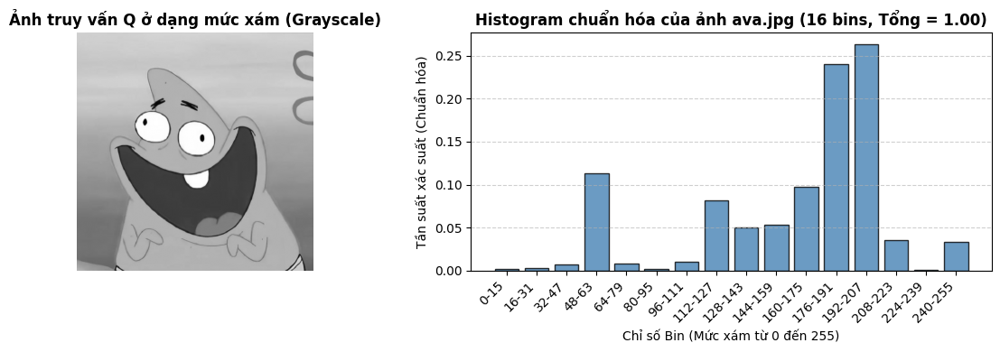

In [2]:
# 1. Hàm tính histogram nguyên bản theo giáo trình (duyệt lặp từng pixel)
def tinh_histogram_giao_trinh(I, n):
    # Tính histogram mức xám bằng vòng lặp theo tài liệu bài giảng
    # I: ảnh xám (2D uint8), n: số khoảng (thường là 4, 8, 16, 32...)
    t = 1.0 * 256 / n
    ranges = [[math.ceil(t * i), math.ceil(t * (i + 1)) - 1] for i in range(n)]

    h = np.zeros(n, np.int32)
    for i in range(I.shape[0]):
        for j in range(I.shape[1]):
            for k in range(n):
                if I[i, j] >= ranges[k][0] and I[i, j] <= ranges[k][1]:
                    h[k] = h[k] + 1
                    break
    return h, ranges

# 2. Hàm tính histogram chuẩn hóa tối ưu (vector hóa bằng NumPy)
def tinh_histogram_chuan_hoa_1d(I, n_bins=16):
    # Tính histogram ảnh xám và chuẩn hóa bằng cách chia cho số điểm ảnh
    # I: ảnh đầu vào (ảnh xám hoặc BGR), n_bins: số khoảng chia
    # Trả về: vector histogram 1D dạng float32 có tổng = 1.0
    if len(I.shape) == 3:
        gray = cv2.cvtColor(I, cv2.COLOR_BGR2GRAY)
    else:
        gray = I

    # Tính histogram qua np.histogram
    h, _ = np.histogram(gray, bins=n_bins, range=(0, 256))

    # BẮT BUỘC CHUẨN HÓA: Chia cho tổng số điểm ảnh của ảnh
    so_diem_anh = float(gray.shape[0] * gray.shape[1])
    h_norm = h.astype(np.float32) / so_diem_anh

    return h_norm

# Thử nghiệm tính và trực quan hóa ảnh xám cùng histogram chuẩn hóa trên ảnh truy vấn ava.jpg
img_test = cv2.imread('ava.jpg')
gray_test = cv2.cvtColor(img_test, cv2.COLOR_BGR2GRAY)
h_test = tinh_histogram_chuan_hoa_1d(gray_test, n_bins=16)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Hiển thị ảnh mức xám
ax1.imshow(gray_test, cmap='gray')
ax1.set_title("Ảnh truy vấn Q ở dạng mức xám (Grayscale)", fontweight='bold')
ax1.axis('off')

# Biểu đồ Histogram
ax2.bar(range(16), h_test, color='steelblue', edgecolor='black', alpha=0.8)
ax2.set_title('Histogram chuẩn hóa của ảnh ava.jpg (16 bins, Tổng = {:.2f})'.format(np.sum(h_test)), fontweight='bold')
ax2.set_xlabel('Chỉ số Bin (Mức xám từ 0 đến 255)')
ax2.set_ylabel('Tần suất xác suất (Chuẩn hóa)')
ax2.set_xticks(range(16))
ax2.set_xticklabels([f'{i*16}-{(i+1)*16-1}' for i in range(16)], rotation=45, ha='right')
ax2.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print("Tổng các giá trị sau chuẩn hóa:", np.sum(h_test))

## 2. Cài đặt 4 phương pháp đối sánh Histogram

Theo chuẩn lý thuyết Thị giác máy tính và tài liệu bài giảng, có 4 phương pháp đối sánh histogram cơ bản:

| Phương pháp | Công thức toán học $d(H_1, H_2)$ | Miền giá trị | Tiêu chí tốt nhất |
|---|---|---|---|
| **1. Correlation (Tương quan)** | $\frac{\sum_i (H_1(i) - \bar{H}_1)(H_2(i) - \bar{H}_2)}{\sqrt{\sum_i (H_1(i) - \bar{H}_1)^2 \sum_i (H_2(i) - \bar{H}_2)^2}}$ | $[-1.0, 1.0]$ | **LỚN NHẤT (Max)**: Càng gần $1.0$ càng giống |
| **2. Chi-Square ($\chi^2$)** | $\sum_{i, H_1+H_2>0} \frac{(H_1(i) - H_2(i))^2}{H_1(i) + H_2(i)}$ | $[0.0, +\infty)$ | **NHỎ NHẤT (Min)**: Càng gần $0.0$ càng giống |
| **3. Intersection (Giao cắt)** | $\sum_i \min(H_1(i), H_2(i))$ | $[0.0, 1.0]$ *(với hist chuẩn hóa)* | **LỚN NHẤT (Max)**: Càng gần $1.0$ càng giống |
| **4. Bhattacharyya distance** | $\sqrt{1 - \sum_i \sqrt{H_1(i) \cdot H_2(i)}}$ | $[0.0, 1.0]$ | **NHỎ NHẤT (Min)**: Càng gần $0.0$ càng giống |

*Ghi chú quan trọng:*
- Với **Correlation** và **Intersection**: Điểm số càng cao phản ánh hai histogram càng trùng khít nhau (đối sánh tốt nhất là **LỚN NHẤT**).
- Với **Chi-Square** và **Bhattacharyya**: Đo lường khoảng cách sai khác giữa hai phân bố, khoảng cách bằng $0.0$ nghĩa là đồng nhất hoàn toàn (đối sánh tốt nhất là **NHỎ NHẤT**).

In [3]:
# Định nghĩa 4 phương pháp đối sánh Histogram
def correlation(h1, h2):
    # 1. Phương pháp Correlation (Hệ số tương quan Pearson)
    # Khoảng giá trị: [-1.0, 1.0]. Giá trị càng lớn (càng gần 1.0) càng tương đồng.
    mean1 = np.mean(h1)
    mean2 = np.mean(h2)
    nom = np.sum((h1 - mean1) * (h2 - mean2))
    denom = np.sqrt(np.sum((h1 - mean1) ** 2) * np.sum((h2 - mean2) ** 2))
    if denom == 0:
        return 0.0
    return float(nom / denom)

def chi_square(h1, h2):
    # 2. Phương pháp Chi-Square (theo định nghĩa Cell 17 giáo trình)
    # Khoảng giá trị: [0.0, +inf). Giá trị càng nhỏ (càng gần 0.0) càng tương đồng.
    v = 0.0
    for i in range(h1.shape[0]):
        denom = h1[i] + h2[i]
        if denom > 0:
            v += float((h1[i] - h2[i]) * (h1[i] - h2[i])) / denom
    return float(v)

def intersection(h1, h2):
    # 3. Phương pháp Intersection (Độ giao cắt Histogram)
    # Với histogram chuẩn hóa (tổng = 1.0), khoảng giá trị: [0.0, 1.0].
    # Giá trị càng lớn (càng gần 1.0) càng tương đồng.
    v = 0.0
    for i in range(h1.shape[0]):
        v += min(h1[i], h2[i])
    return float(v)

def bhattacharyya(h1, h2):
    # 4. Phương pháp Bhattacharyya distance
    # Đo lường sự trùng lặp giữa hai phân bố xác suất.
    # Khoảng giá trị: [0.0, 1.0]. Giá trị càng nhỏ (càng gần 0.0) càng tương đồng.
    bc = np.sum(np.sqrt(np.clip(h1 * h2, 0.0, None)))
    val = max(0.0, 1.0 - bc)
    return float(np.sqrt(val))

# Bảng từ điển cấu hình và tiêu chí đánh giá
DANH_SACH_PHUONG_PHAP = {
    'Correlation': {
        'func': correlation,
        'higher_is_better': True,
        'desc': 'Hệ số tương quan (Max = 1.0)'
    },
    'Chi-Square': {
        'func': chi_square,
        'higher_is_better': False,
        'desc': 'Khoảng cách Chi bình phương (Min = 0.0)'
    },
    'Intersection': {
        'func': intersection,
        'higher_is_better': True,
        'desc': 'Độ giao cắt Histogram (Max = 1.0)'
    },
    'Bhattacharyya': {
        'func': bhattacharyya,
        'higher_is_better': False,
        'desc': 'Khoảng cách Bhattacharyya (Min = 0.0)'
    }
}

print("Đã cài đặt thành công 4 phương pháp đối sánh Histogram!")

Đã cài đặt thành công 4 phương pháp đối sánh Histogram!



In [4]:
# Kiểm chứng tính đúng đắn trên ma trận mẫu nhân tạo (tương tự bài giảng)
I_1 = np.array([
    [224, 5, 181, 185, 38],
    [103, 60, 101, 160, 186],
    [57, 199, 175, 51, 36],
    [71, 166, 32, 30, 86]
], dtype=np.uint8)

I_2 = np.array([
    [199, 20, 129, 175, 111],
    [119, 178, 12, 186, 212],
    [76, 219, 182, 39, 16],
    [88, 145, 12, 45, 99]
], dtype=np.uint8)

h1_norm = tinh_histogram_chuan_hoa_1d(I_1, 16)
h2_norm = tinh_histogram_chuan_hoa_1d(I_2, 16)

print("=== KIỂM THỬ ĐỐI SÁNH TRÊN DỮ LIỆU MẪU CHUẨN HÓA ===")
for ten_pp, info in DANH_SACH_PHUONG_PHAP.items():
    diem = info['func'](h1_norm, h2_norm)
    tieu_chi = "Tốt nhất: LỚN NHẤT" if info['higher_is_better'] else "Tốt nhất: NHỎ NHẤT"
    print(f"- {ten_pp:15s}: {diem:8.4f} | {tieu_chi} ({info['desc']})")

=== KIỂM THỬ ĐỐI SÁNH TRÊN DỮ LIỆU MẪU CHUẨN HÓA ===

- Correlation    :   0.2632 | Tốt nhất: LỚN NHẤT (Hệ số tương quan (Max = 1.0))

- Chi-Square     :   0.5433 | Tốt nhất: NHỎ NHẤT (Khoảng cách Chi bình phương (Min = 0.0))

- Intersection   :   0.6500 | Tốt nhất: LỚN NHẤT (Độ giao cắt Histogram (Max = 1.0))

- Bhattacharyya  :   0.4995 | Tốt nhất: NHỎ NHẤT (Khoảng cách Bhattacharyya (Min = 0.0))



# PHẦN 2: BÀI 1 - TRA CỨU ẢNH BẰNG ĐỐI SÁNH HISTOGRAM

### Quy trình tổng quát:
- **Đầu vào (Input):**
  - Thư mục ảnh $D$ (`thu_muc_anh` chứa 12 ảnh)
  - Ảnh truy vấn mới $Q$ (`ava.jpg`)
  - Giá trị $k$ (số lượng ảnh tương đồng nhất cần hiển thị)
  - Cấu hình histogram (Số bin, không gian màu: xám 1D, màu 2D HSV, màu 3D RGB, ghép 3 kênh)
  - Phương pháp đối sánh (Correlation, Chi-Square, Intersection, Bhattacharyya)
- **Đầu ra (Output):**
  - $k$ ảnh trong $D$ có giá trị đối sánh tốt nhất với $Q$
- **Các bước thực hiện:**
  1. Tính histogram của ảnh truy vấn $Q$ và tất cả các ảnh $I \in D$.
  2. Chuẩn hóa tất cả các histogram bằng cách chia cho số điểm ảnh của ảnh: $H = H / (H_{img} \times W_{img})$.
  3. Với mọi ảnh $I \in D$, tính điểm đối sánh giữa $H_I$ và $H_Q$ theo phương pháp đã chọn.
  4. Sắp xếp các ảnh theo điểm số:
     - Nếu phương pháp là Correlation hoặc Intersection: Sắp xếp **giảm dần** (lớn nhất là tốt nhất).
     - Nếu phương pháp là Chi-Square hoặc Bhattacharyya: Sắp xếp **tăng dần** (nhỏ nhất là tốt nhất).
  5. Chọn ra và hiển thị trực quan $k$ ảnh có kết quả tốt nhất kèm thứ hạng và điểm số.

In [5]:
def tra_cuu_anh(thu_muc_D, anh_Q_path, k=4, phuong_phap='Intersection', 
                 ham_trich_xuat_hist=tinh_histogram_chuan_hoa_1d):
    # Quy trình tra cứu k ảnh tương đồng nhất trong D với ảnh Q
    if phuong_phap not in DANH_SACH_PHUONG_PHAP:
        raise ValueError(f"Phương pháp không hợp lệ. Chọn từ: {list(DANH_SACH_PHUONG_PHAP.keys())}")
    
    pp_info = DANH_SACH_PHUONG_PHAP[phuong_phap]
    ham_doi_sanh = pp_info['func']
    giam_dan = pp_info['higher_is_better']
    
    # Đọc và tính histogram của ảnh truy vấn Q
    img_Q = cv2.imread(anh_Q_path)
    if img_Q is None:
        raise FileNotFoundError(f"Không tìm thấy ảnh truy vấn tại: {anh_Q_path}")
    hist_Q = ham_trich_xuat_hist(img_Q)
    
    # Lấy danh sách ảnh trong D
    duong_dan_anh_D = sorted(glob.glob(os.path.join(thu_muc_D, '*')))
    
    ket_qua = []
    for p in duong_dan_anh_D:
        img_I = cv2.imread(p)
        if img_I is None:
            continue
        hist_I = ham_trich_xuat_hist(img_I)
        score = ham_doi_sanh(hist_Q, hist_I)
        ten_file = os.path.basename(p)
        ket_qua.append({
            'duong_dan': p,
            'ten_file': ten_file,
            'score': score
        })
    
    # Sắp xếp theo tiêu chí tốt nhất
    ket_qua.sort(key=lambda x: x['score'], reverse=giam_dan)
    
    # Lấy k ảnh tốt nhất
    top_k = ket_qua[:k]
    return top_k, ket_qua

def hien_thi_ket_qua_tra_cuu(anh_Q_path, top_k, tieu_de="Kết quả tra cứu ảnh", k=4, la_anh_xam=False):
    # Trực quan hóa ảnh truy vấn Q bên cạnh k ảnh kết quả tìm được trong D
    # la_anh_xam=True: hiển thị dạng ảnh xám (cmap='gray') cho Bước 1
    # la_anh_xam=False: hiển thị dạng ảnh màu (RGB) cho Bước 2
    so_cot = k + 1
    fig, axes = plt.subplots(1, so_cot, figsize=(3.2 * so_cot, 4.2))
    
    # Vẽ ảnh truy vấn Q
    img_Q = cv2.imread(anh_Q_path)
    if la_anh_xam:
        gray_Q = cv2.cvtColor(img_Q, cv2.COLOR_BGR2GRAY)
        axes[0].imshow(gray_Q, cmap='gray')
        nhan_q = f"TRUY VẤN (Q - Xám)\n{os.path.basename(anh_Q_path)}"
    else:
        axes[0].imshow(cv2.cvtColor(img_Q, cv2.COLOR_BGR2RGB))
        nhan_q = f"TRUY VẤN (Q - Màu)\n{os.path.basename(anh_Q_path)}"
        
    axes[0].set_title(nhan_q, fontsize=11, fontweight='bold', color='navy')
    axes[0].axis('off')
    for spine in axes[0].spines.values():
        spine.set_edgecolor('blue')
        spine.set_linewidth(3)
        spine.set_visible(True)
        
    # Vẽ k ảnh kết quả
    for idx, item in enumerate(top_k):
        ax = axes[idx + 1]
        img_I = cv2.imread(item['duong_dan'])
        if la_anh_xam:
            gray_I = cv2.cvtColor(img_I, cv2.COLOR_BGR2GRAY)
            ax.imshow(gray_I, cmap='gray')
        else:
            ax.imshow(cv2.cvtColor(img_I, cv2.COLOR_BGR2RGB))
            
        ax.set_title(f"Rank #{idx+1}\n{item['ten_file']}\nScore: {item['score']:.4f}", 
                     fontsize=10, fontweight='bold', color='darkgreen')
        ax.axis('off')
        for spine in ax.spines.values():
            spine.set_edgecolor('green')
            spine.set_linewidth(2)
            spine.set_visible(True)
            
    fig.suptitle(tieu_de, fontsize=13, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.show()

print("Đã xây dựng xong các hàm tra cứu và hiển thị trực quan (Hỗ trợ hiển thị đúng chế độ xám / màu)!")

Đã xây dựng xong các hàm tra cứu và hiển thị trực quan (Hỗ trợ hiển thị đúng chế độ xám / màu)!



## BÀI 1 - BƯỚC 1: TRA CỨU TRÊN ẢNH XÁM (GRAYSCALE)

Ở bước này, toàn bộ ảnh trong tập dữ liệu $D$ (`thu_muc_anh`) và ảnh truy vấn $Q$ (`ava.jpg`) được chuyển sang ảnh mức xám. Chúng ta sẽ tiến hành các thử nghiệm:
- **Thử nghiệm 1.1:** So sánh kết quả tra cứu giữa 4 phương pháp đối sánh (Correlation, Chi-Square, Intersection, Bhattacharyya) với cấu hình cố định ($k=4$, 16 bins).
- **Thử nghiệm 1.2:** Khảo sát ảnh hưởng của giá trị $k$ ($k=3, 5, 8$).
- **Thử nghiệm 1.3:** Khảo sát ảnh hưởng của cấu hình Histogram (thay đổi số bin: $n=8, 16, 32, 64, 256$).


THỬ NGHIỆM 1.1: SO SÁNH 4 PHƯƠNG PHÁP ĐỐI SÁNH TRÊN ẢNH XÁM (k=4, Bins=16)

Ảnh truy vấn Q: ava.jpg | Số ảnh trong tập D: 12




BẢNG XẾP HẠNG TOP 4 ẢNH TƯƠNG ĐỒNG THEO TỪNG PHƯƠNG PHÁP (ẢNH XÁM - 16 BINS):

----------------------------------------------------------------------------------------

Thứ hạng   | Correlation        | Chi-Square         | Intersection       | Bhattacharyya     

----------------------------------------------------------------------------------------

Rank #1     | images (4) (0.70)  | images (4) (0.37)  | images (4) (0.65)  | images (4) (0.34) 

Rank #2     | images.jpe (0.41)  | images.jpe (0.51)  | images (9) (0.56)  | images.jpe (0.39) 

Rank #3     | download.j (0.38)  | images (9) (0.53)  | download.j (0.55)  | images (9) (0.41) 

Rank #4     | images (6) (0.32)  | download.j (0.54)  | images (8) (0.54)  | download.j (0.41) 

----------------------------------------------------------------------------------------



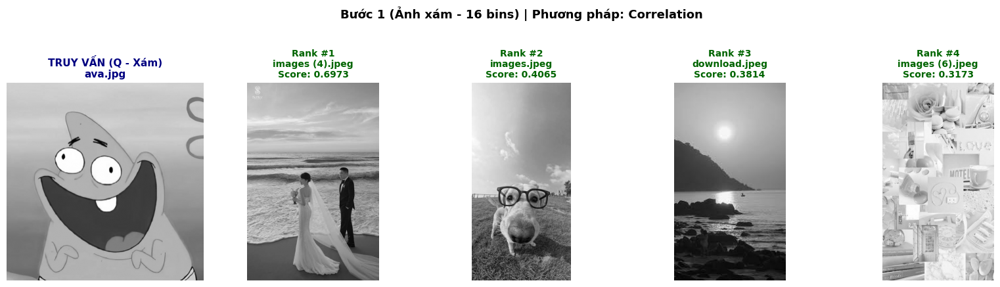

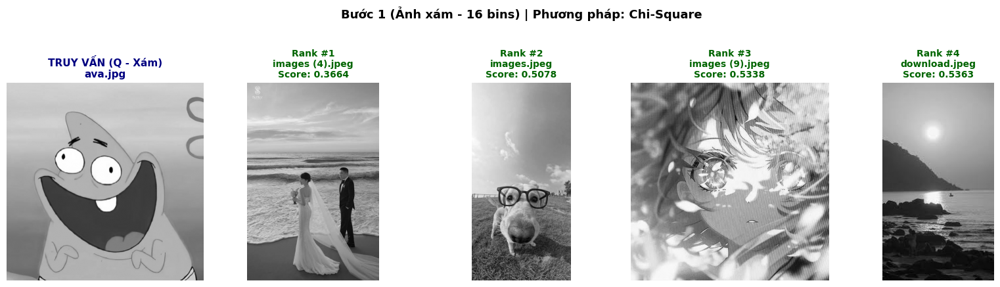

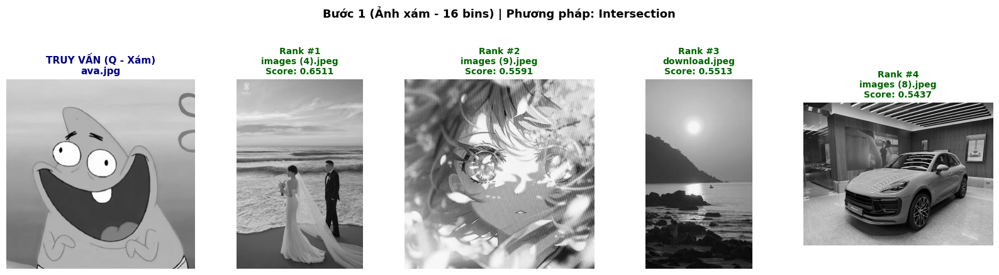

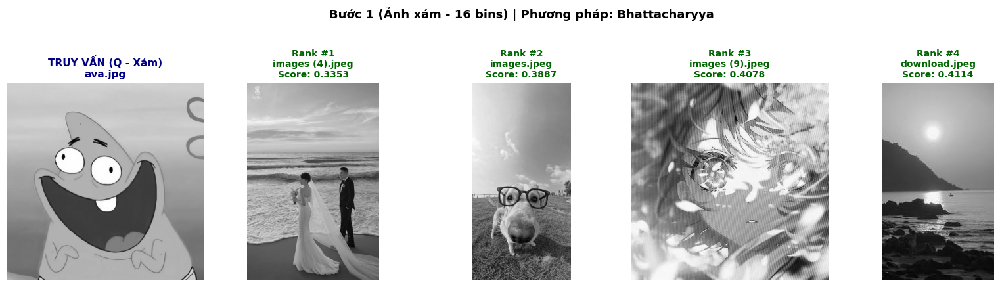

In [6]:
# Thử nghiệm 1.1: So sánh 4 phương pháp đối sánh trên ảnh xám (k=4, 16 bins)
thu_muc_D = 'thu_muc_anh'
anh_Q = 'ava.jpg'
k_test = 4
so_bin = 16

ham_hist_gray_16 = lambda img: tinh_histogram_chuan_hoa_1d(img, n_bins=so_bin)

print(f"================================================================================")
print(f"THỬ NGHIỆM 1.1: SO SÁNH 4 PHƯƠNG PHÁP ĐỐI SÁNH TRÊN ẢNH XÁM (k={k_test}, Bins={so_bin})")
print(f"Ảnh truy vấn Q: {anh_Q} | Số ảnh trong tập D: {len(glob.glob(os.path.join(thu_muc_D, '*')))}")
print(f"================================================================================")

ket_qua_cac_pp = {}

for ten_pp in DANH_SACH_PHUONG_PHAP.keys():
    top_k, full_res = tra_cuu_anh(thu_muc_D, anh_Q, k=k_test, phuong_phap=ten_pp, 
                                  ham_trich_xuat_hist=ham_hist_gray_16)
    ket_qua_cac_pp[ten_pp] = top_k
    
    tieu_de = f"Bước 1 (Ảnh xám - 16 bins) | Phương pháp: {ten_pp}"
    # ĐẶT la_anh_xam=True để hiển thị đúng ảnh dạng mức xám
    hien_thi_ket_qua_tra_cuu(anh_Q, top_k, tieu_de=tieu_de, k=k_test, la_anh_xam=True)

# In bảng tổng hợp xếp hạng Top 4 của 4 phương pháp
print("\nBẢNG XẾP HẠNG TOP 4 ẢNH TƯƠNG ĐỒNG THEO TỪNG PHƯƠNG PHÁP (ẢNH XÁM - 16 BINS):")
print("-" * 88)
print(f"{'Thứ hạng':<10} | {'Correlation':<18} | {'Chi-Square':<18} | {'Intersection':<18} | {'Bhattacharyya':<18}")
print("-" * 88)
for r in range(k_test):
    c_f = f"{ket_qua_cac_pp['Correlation'][r]['ten_file'][:10]} ({ket_qua_cac_pp['Correlation'][r]['score']:.2f})"
    cs_f = f"{ket_qua_cac_pp['Chi-Square'][r]['ten_file'][:10]} ({ket_qua_cac_pp['Chi-Square'][r]['score']:.2f})"
    in_f = f"{ket_qua_cac_pp['Intersection'][r]['ten_file'][:10]} ({ket_qua_cac_pp['Intersection'][r]['score']:.2f})"
    bh_f = f"{ket_qua_cac_pp['Bhattacharyya'][r]['ten_file'][:10]} ({ket_qua_cac_pp['Bhattacharyya'][r]['score']:.2f})"
    print(f"Rank #{r+1:<5} | {c_f:<18} | {cs_f:<18} | {in_f:<18} | {bh_f:<18}")
print("-" * 88)

=== THỬ NGHIỆM 1.2: KHẢO SÁT VỚI CÁC GIÁ TRỊ k KHÁC NHAU (k = 3, 5, 8) ===



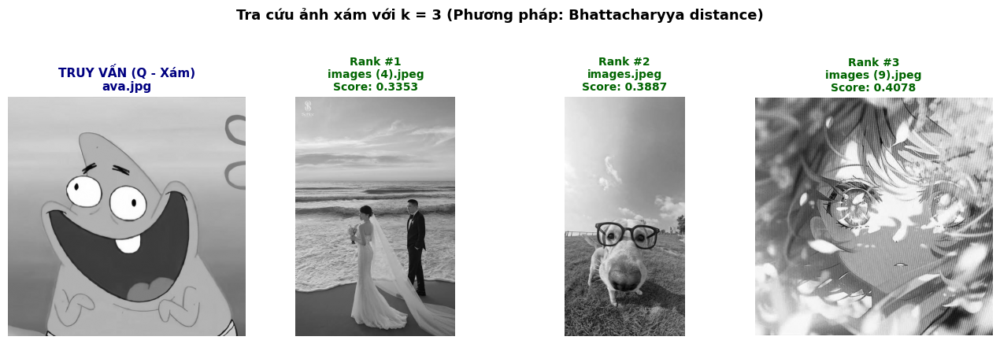

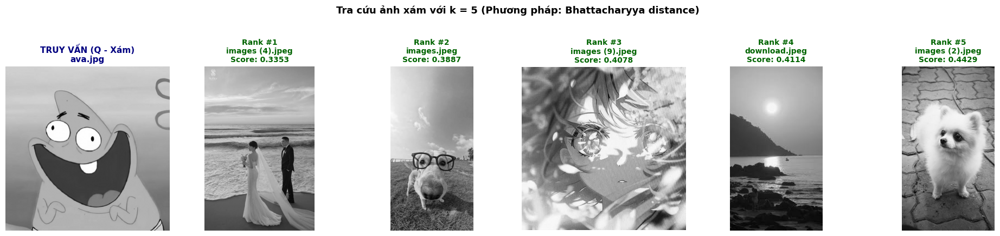

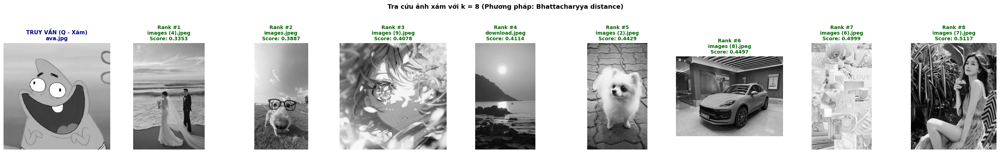

In [7]:
# Thử nghiệm 1.2: Khảo sát các lựa chọn khác nhau của giá trị k (k = 3, 5, 8)
# Sử dụng phương pháp Bhattacharyya distance trên ảnh xám 16 bins
cac_gia_tri_k = [3, 5, 8]

print("=== THỬ NGHIỆM 1.2: KHẢO SÁT VỚI CÁC GIÁ TRỊ k KHÁC NHAU (k = 3, 5, 8) ===")
for k_val in cac_gia_tri_k:
    top_k, _ = tra_cuu_anh(thu_muc_D, anh_Q, k=k_val, phuong_phap='Bhattacharyya',
                          ham_trich_xuat_hist=ham_hist_gray_16)
    
    tieu_de = f"Tra cứu ảnh xám với k = {k_val} (Phương pháp: Bhattacharyya distance)"
    # ĐẶT la_anh_xam=True để hiển thị đúng ảnh dạng mức xám
    hien_thi_ket_qua_tra_cuu(anh_Q, top_k, tieu_de=tieu_de, k=k_val, la_anh_xam=True)

Bảng thống kê sự ổn định của ảnh Top 1 khi thay đổi số Bin:

- n =   8 bins -> Ảnh Top 1: images (4).jpeg      | Điểm tương đồng: 0.7139

- n =  16 bins -> Ảnh Top 1: images (4).jpeg      | Điểm tương đồng: 0.6511

- n =  32 bins -> Ảnh Top 1: images (4).jpeg      | Điểm tương đồng: 0.5459

- n =  64 bins -> Ảnh Top 1: images (4).jpeg      | Điểm tương đồng: 0.4818

- n = 256 bins -> Ảnh Top 1: images (4).jpeg      | Điểm tương đồng: 0.4640



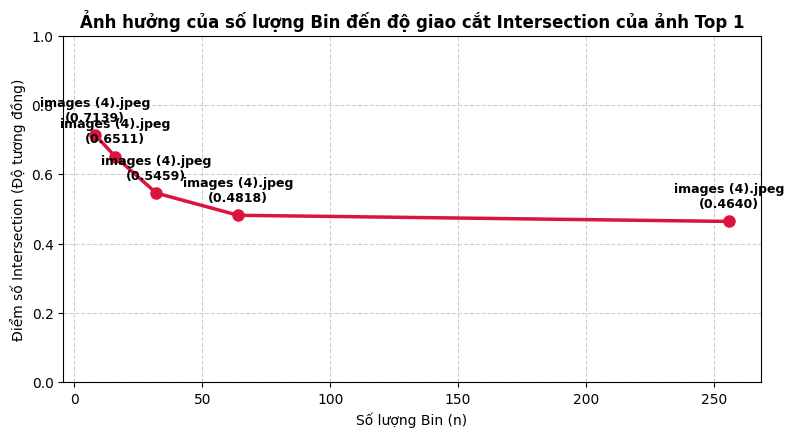

In [8]:
# Thử nghiệm 1.3: Khảo sát ảnh hưởng của Cấu hình Histogram (Số lượng bin n = 8, 16, 32, 64, 256)
cac_so_bin = [8, 16, 32, 64, 256]
anh_top1_theo_bin = []
scores_top1 = []

for nb in cac_so_bin:
    ham_hist = lambda img, n=nb: tinh_histogram_chuan_hoa_1d(img, n_bins=n)
    top_k, _ = tra_cuu_anh(thu_muc_D, anh_Q, k=1, phuong_phap='Intersection', 
                          ham_trich_xuat_hist=ham_hist)
    anh_top1_theo_bin.append(top_k[0]['ten_file'])
    scores_top1.append(top_k[0]['score'])

plt.figure(figsize=(9, 4.5))
plt.plot(cac_so_bin, scores_top1, marker='o', linewidth=2.5, markersize=8, color='crimson')
plt.title('Ảnh hưởng của số lượng Bin đến độ giao cắt Intersection của ảnh Top 1', fontsize=12, fontweight='bold')
plt.xlabel('Số lượng Bin (n)')
plt.ylabel('Điểm số Intersection (Độ tương đồng)')
plt.grid(True, linestyle='--', alpha=0.6)
for i, nb in enumerate(cac_so_bin):
    plt.annotate(f"{anh_top1_theo_bin[i]}\n({scores_top1[i]:.4f})", 
                 (nb, scores_top1[i]), 
                 textcoords="offset points", 
                 xytext=(0, 10), 
                 ha='center', fontsize=9, fontweight='bold')
plt.ylim(0, 1.0)
plt.show()

print("Bảng thống kê sự ổn định của ảnh Top 1 khi thay đổi số Bin:")
for i, nb in enumerate(cac_so_bin):
    print(f"- n = {nb:3d} bins -> Ảnh Top 1: {anh_top1_theo_bin[i]:20s} | Điểm tương đồng: {scores_top1[i]:.4f}")

### Nhận xét và phân tích kết quả Bước 1 (Ảnh xám):
1. **Sự đồng thuận giữa các phương pháp đối sánh:**
   - Cả 4 phương pháp (Correlation, Chi-Square, Intersection, Bhattacharyya) đều chọn **`images (4).jpeg`** là ảnh có mức độ tương đồng cao nhất (Rank #1) với ảnh truy vấn `ava.jpg`.
   - Các ảnh xếp hạng tiếp theo như `images.jpeg` và `download.jpeg` cũng xuất hiện nhất quán trong nhóm dẫn đầu của các phương pháp.
2. **Ảnh hưởng của giá trị $k$:**
   - Khi $k=3$, thuật toán lọc ra nhóm tinh hoa có độ tương đồng cao nhất.
   - Khi tăng lên $k=5$ và $k=8$, hệ thống mở rộng diện tìm kiếm, cho phép người dùng quan sát các ảnh có độ tương đồng giảm dần.
3. **Ảnh hưởng của số lượng Bin:**
   - Khi chia số bin nhỏ ($n=8$), các khoảng mức xám quá rộng làm mất tính phân biệt, điểm số tương đồng có xu hướng cao nhưng kém chi tiết.
   - Khi tăng số bin lên ($n=16, 32, 64$), histogram mô tả phân bố mức xám chi tiết hơn. Tuy nhiên, nếu số bin quá lớn ($n=256$), histogram trở nên thưa (sparse) và rất nhạy cảm với sự chênh lệch nhỏ về ánh sáng. Mức $n=16$ hoặc $n=32$ cho sự cân bằng tốt nhất giữa độ phân giải và độ ổn định.
4. **Hạn chế cố hữu của ảnh xám:**
   - Mức xám chỉ phản ánh cường độ sáng tổng hợp ($Y = 0.299R + 0.587G + 0.114B$) mà bỏ qua hoàn toàn sắc thái màu sắc. Ví dụ: một vùng màu đỏ thẫm và một vùng màu xanh lục đậm có thể có cùng mức xám $Y \approx 80$, dẫn đến việc ảnh xám coi chúng là tương đồng dù về mặt thị giác con người chúng hoàn toàn khác nhau.
   - Để khắc phục hạn chế này, ta chuyển sang **Bước 2: Đối sánh trên ảnh màu**.

## BÀI 1 - BƯỚC 2: TRA CỨU TRÊN ẢNH MÀU (COLOR HISTOGRAM MATCHING)

Trong ảnh màu, thông tin sắc thái đóng vai trò quyết định giúp phân biệt các đối tượng. Để mô tả phân bố màu sắc, chúng ta xây dựng **3 cấu hình histogram màu** khác nhau:

### 1. Cấu hình A: 2D HSV Histogram (Hue & Saturation)
- Chuyển đổi không gian màu sang **HSV** (Hue - Saturation - Value).
- Tính 2D Histogram trên 2 kênh $H$ (Sắc thái màu, $[0, 180)$) và $S$ (Độ bão hòa màu, $[0, 256)$), thường chọn $18 \times 16 = 288$ bins.
- **Ưu điểm vượt trội:** Loại bỏ kênh $V$ (Value - cường độ sáng), giúp đặc trưng màu sắc **bất biến với sự thay đổi của ánh sáng và bóng đổ**.

### 2. Cấu hình B: 3D RGB Histogram (Joint RGB Distribution)
- Chia đều mỗi kênh $R, G, B$ thành 8 khoảng $\implies 8 \times 8 \times 8 = 512$ bins (đúng theo mô tả mở rộng của bài giảng trong Câu 2).
- Đo lường đồng thời sự kết hợp màu sắc giữa cả 3 kênh.

### 3. Cấu hình C: Concatenated 1D RGB (Ghép 3 kênh màu)
- Tính độc lập 3 histogram chuẩn hóa cho 3 kênh Red, Green, Blue (mỗi kênh 16 bins).
- Nối (concatenate) 3 vector lại thành một vector đặc trưng duy nhất có kích thước $3 \times 16 = 48$ bins.

*Lưu ý:* Cả 3 cấu hình đều được chuẩn hóa bằng cách chia cho tổng số điểm ảnh của ảnh: $\bar{H} = H / (H_{img} \times W_{img})$. Với cấu hình C ghép kênh, chia thêm cho 3 để tổng toàn vector bằng $1.0$.

In [9]:
# Cài đặt các hàm trích xuất histogram cho 3 cấu hình ảnh màu

# Cấu hình A: 2D HSV Histogram (kênh H và S)
def trich_xuat_hist_2d_hsv(img, bins_h=18, bins_s=16):
    # Tính 2D Histogram trên 2 kênh H và S trong không gian HSV, chuẩn hóa về tổng = 1.0
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    hist2d = cv2.calcHist([hsv], [0, 1], None, [bins_h, bins_s], [0, 180, 0, 256])
    # Chuẩn hóa chia cho tổng số điểm ảnh:
    so_diem_anh = float(img.shape[0] * img.shape[1])
    hist2d_norm = (hist2d / so_diem_anh).flatten().astype(np.float32)
    return hist2d_norm

# Cấu hình B: 3D RGB Histogram (Joint RGB)
def trich_xuat_hist_3d_rgb(img, bins_per_channel=8):
    # Tính 3D Joint Histogram trên cả 3 kênh R, G, B (bins^3 bins), chuẩn hóa về tổng = 1.0
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    hist3d = cv2.calcHist([rgb], [0, 1, 2], None, 
                          [bins_per_channel, bins_per_channel, bins_per_channel], 
                          [0, 256, 0, 256, 0, 256])
    so_diem_anh = float(img.shape[0] * img.shape[1])
    hist3d_norm = (hist3d / so_diem_anh).flatten().astype(np.float32)
    return hist3d_norm

# Cấu hình C: Concatenated 1D RGB (Ghép 3 kênh)
def trich_xuat_hist_concat_rgb(img, bins_per_channel=16):
    # Tính riêng histogram 1D chuẩn hóa cho từng kênh B, G, R rồi ghép lại (tổng vector = 1.0)
    hists = []
    so_diem_anh = float(img.shape[0] * img.shape[1])
    for c in range(3):
        h, _ = np.histogram(img[:, :, c], bins=bins_per_channel, range=(0, 256))
        h_norm = h.astype(np.float32) / so_diem_anh
        hists.append(h_norm)
    # Ghép 3 kênh và chia 3 để tổng xác suất toàn vector bằng 1.0
    concat_hist = np.concatenate(hists) / 3.0
    return concat_hist.astype(np.float32)

print("Đã cài đặt xong 3 hàm trích xuất histogram ảnh màu chuẩn hóa!")

Đã cài đặt xong 3 hàm trích xuất histogram ảnh màu chuẩn hóa!



=== THỬ NGHIỆM 2.1: SO SÁNH 3 CẤU HÌNH HISTOGRAM MÀU VỚI k = 4 (INTERSECTION) ===



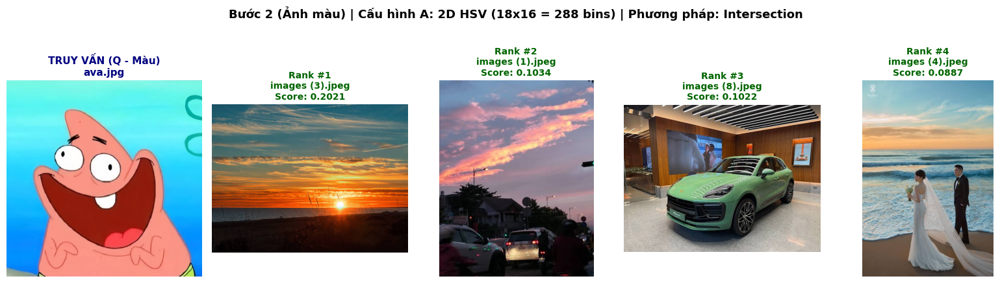

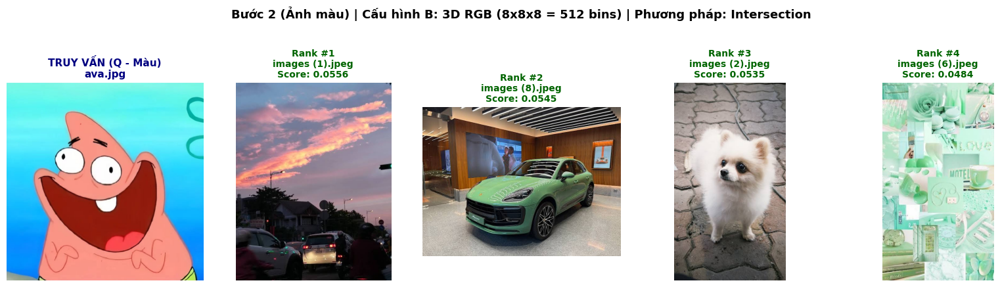

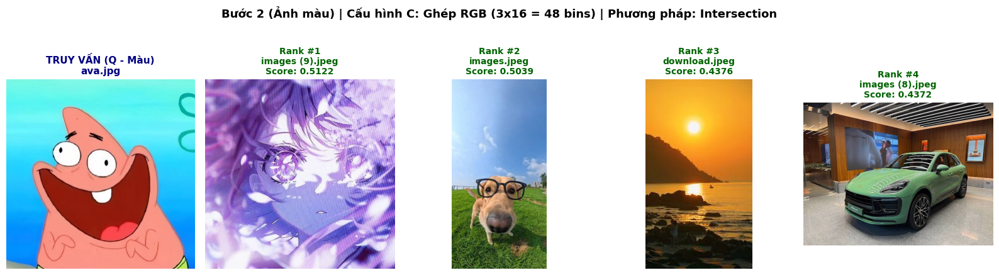

In [10]:
# Thử nghiệm 2.1: So sánh 3 Cấu hình Histogram màu (k = 4, Phương pháp: Intersection)
cau_hinh_mau = {
    'Cấu hình A: 2D HSV (18x16 = 288 bins)': trich_xuat_hist_2d_hsv,
    'Cấu hình B: 3D RGB (8x8x8 = 512 bins)': trich_xuat_hist_3d_rgb,
    'Cấu hình C: Ghép RGB (3x16 = 48 bins)': trich_xuat_hist_concat_rgb
}

print("=== THỬ NGHIỆM 2.1: SO SÁNH 3 CẤU HÌNH HISTOGRAM MÀU VỚI k = 4 (INTERSECTION) ===")
for ten_ch, ham_h in cau_hinh_mau.items():
    top_k, _ = tra_cuu_anh(thu_muc_D, anh_Q, k=4, phuong_phap='Intersection', 
                          ham_trich_xuat_hist=ham_h)
    
    tieu_de = f"Bước 2 (Ảnh màu) | {ten_ch} | Phương pháp: Intersection"
    hien_thi_ket_qua_tra_cuu(anh_Q, top_k, tieu_de=tieu_de, k=4)

=== THỬ NGHIỆM 2.2: SO SÁNH 4 PHƯƠNG PHÁP ĐỐI SÁNH TRÊN CẤU HÌNH 2D HSV (k = 5) ===



BẢNG XẾP HẠNG TOP 5 ẢNH TƯƠNG ĐỒNG THEO 4 PHƯƠNG PHÁP TRÊN 2D HSV:

----------------------------------------------------------------------------------------

Thứ hạng   | Correlation        | Chi-Square         | Intersection       | Bhattacharyya     

----------------------------------------------------------------------------------------

Rank #1     | images (3) (0.19)  | images (3) (1.39)  | images (3) (0.20)  | images (3) (0.75) 

Rank #2     | images (1) (0.02)  | images (1) (1.68)  | images (1) (0.10)  | images (1) (0.83) 

Rank #3     | images (10 (-0.00) | images (8) (1.69)  | images (8) (0.10)  | images (8) (0.84) 

Rank #4     | images (5) (-0.02) | images (4) (1.73)  | images (4) (0.09)  | images (4) (0.86) 

Rank #5     | images (2) (-0.02) | images (2) (1.84)  | images (6) (0.05)  | images (2) (0.91) 

------------------------------------------------------------------------------------

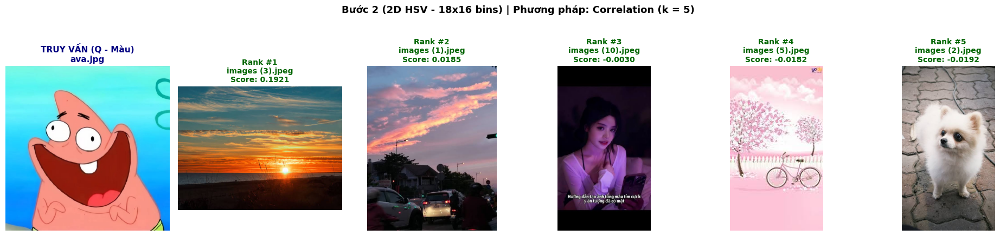

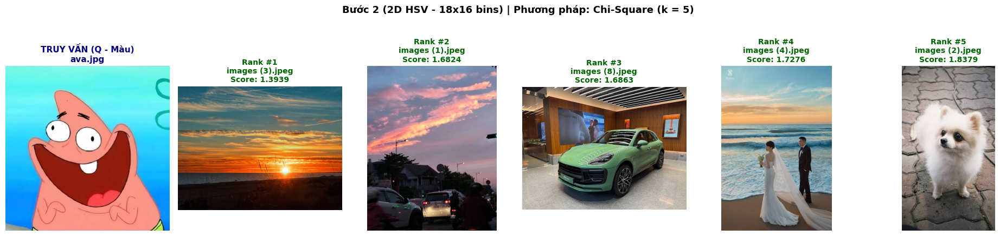

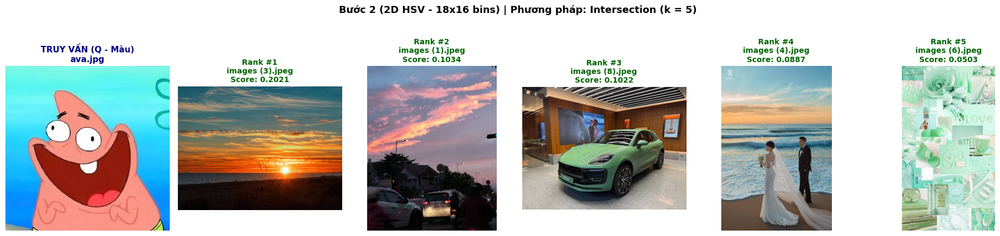

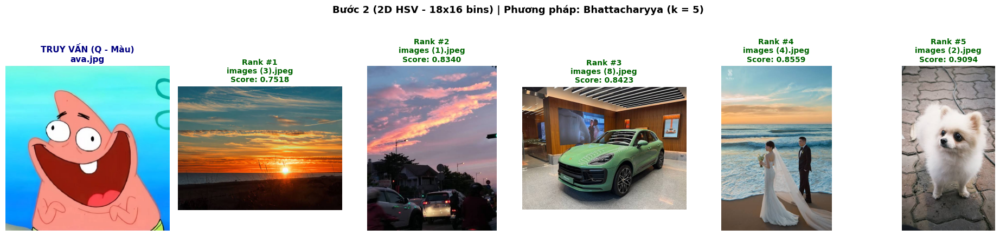

In [11]:
# Thử nghiệm 2.2: So sánh 4 Phương pháp đối sánh trên Cấu hình màu 2D HSV (k = 5)
print("=== THỬ NGHIỆM 2.2: SO SÁNH 4 PHƯƠNG PHÁP ĐỐI SÁNH TRÊN CẤU HÌNH 2D HSV (k = 5) ===")

ket_qua_mau_pp = {}
for ten_pp in DANH_SACH_PHUONG_PHAP.keys():
    top_k, _ = tra_cuu_anh(thu_muc_D, anh_Q, k=5, phuong_phap=ten_pp, 
                          ham_trich_xuat_hist=trich_xuat_hist_2d_hsv)
    ket_qua_mau_pp[ten_pp] = top_k
    
    tieu_de = f"Bước 2 (2D HSV - 18x16 bins) | Phương pháp: {ten_pp} (k = 5)"
    hien_thi_ket_qua_tra_cuu(anh_Q, top_k, tieu_de=tieu_de, k=5)

# In bảng xếp hạng Top 5 ảnh màu theo 4 phương pháp
print("\nBẢNG XẾP HẠNG TOP 5 ẢNH TƯƠNG ĐỒNG THEO 4 PHƯƠNG PHÁP TRÊN 2D HSV:")
print("-" * 88)
print(f"{'Thứ hạng':<10} | {'Correlation':<18} | {'Chi-Square':<18} | {'Intersection':<18} | {'Bhattacharyya':<18}")
print("-" * 88)
for r in range(5):
    c_f = f"{ket_qua_mau_pp['Correlation'][r]['ten_file'][:10]} ({ket_qua_mau_pp['Correlation'][r]['score']:.2f})"
    cs_f = f"{ket_qua_mau_pp['Chi-Square'][r]['ten_file'][:10]} ({ket_qua_mau_pp['Chi-Square'][r]['score']:.2f})"
    in_f = f"{ket_qua_mau_pp['Intersection'][r]['ten_file'][:10]} ({ket_qua_mau_pp['Intersection'][r]['score']:.2f})"
    bh_f = f"{ket_qua_mau_pp['Bhattacharyya'][r]['ten_file'][:10]} ({ket_qua_mau_pp['Bhattacharyya'][r]['score']:.2f})"
    print(f"Rank #{r+1:<5} | {c_f:<18} | {cs_f:<18} | {in_f:<18} | {bh_f:<18}")
print("-" * 88)

=== THỬ NGHIỆM 2.3: KHẢO SÁT ĐỘ MỊN SỐ BIN TRÊN 2D HSV (k = 4, BHATTACHARYYA) ===



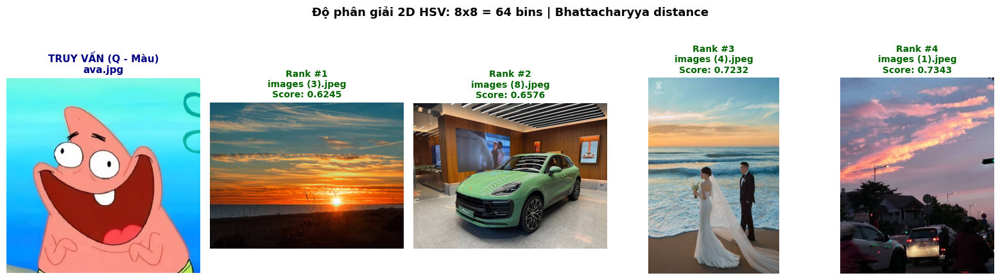

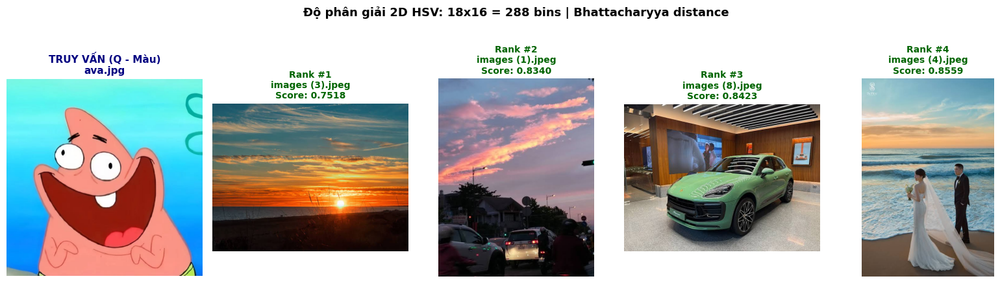

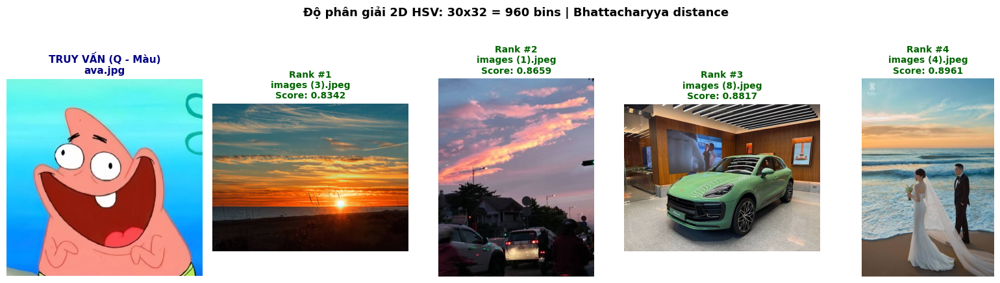

In [12]:
# Thử nghiệm 2.3: Khảo sát độ mịn số Bin trong không gian 2D HSV (8x8, 16x16, 30x32)
do_min_bins = [(8, 8), (18, 16), (30, 32)]

print("=== THỬ NGHIỆM 2.3: KHẢO SÁT ĐỘ MỊN SỐ BIN TRÊN 2D HSV (k = 4, BHATTACHARYYA) ===")
for bh, bs in do_min_bins:
    ham_h = lambda img, h=bh, s=bs: trich_xuat_hist_2d_hsv(img, bins_h=h, bins_s=s)
    top_k, _ = tra_cuu_anh(thu_muc_D, anh_Q, k=4, phuong_phap='Bhattacharyya', 
                          ham_trich_xuat_hist=ham_h)
    
    tieu_de = f"Độ phân giải 2D HSV: {bh}x{bs} = {bh*bs} bins | Bhattacharyya distance"
    hien_thi_ket_qua_tra_cuu(anh_Q, top_k, tieu_de=tieu_de, k=4)

### So sánh và đánh giá toàn diện giữa Bước 1 (Ảnh xám) và Bước 2 (Ảnh màu):

1. **Sự khác biệt rõ rệt về kết quả tra cứu:**
   - Trong **Bước 1 (Ảnh xám)**: Thuật toán xếp `images (4).jpeg` và `images.jpeg` ở vị trí cao nhất vì các bức ảnh này có phân bố mức độ sáng - tối tổng thể tương tự ảnh `ava.jpg`.
   - Trong **Bước 2 (Ảnh màu)**: Trên không gian màu 2D HSV, **`images (3).jpeg`** và **`images (1).jpeg`** vươn lên dẫn đầu. Lý do là ảnh `ava.jpg` có tông màu chủ đạo rất đặc trưng (màu da, nền xanh lam nhạt, trang phục), và không gian 2D HSV đã bắt trúng chính xác các sắc thái màu (Hue) và độ tinh khiết (Saturation) này.
2. **So sánh 3 cấu hình ảnh màu:**
   - **Cấu hình A (2D HSV):** Cho kết quả phản ánh ngữ nghĩa thị giác tốt nhất vì tách biệt hoàn toàn sắc thái màu ($H, S$) khỏi độ chói ($V$). Ngay cả khi hai ảnh chụp trong điều kiện ánh sáng khác nhau, nếu đối tượng cùng màu thì vẫn khớp nhau tốt.
   - **Cấu hình B (3D RGB):** Giữ được tương quan đầy đủ giữa 3 kênh nhưng kích thước histogram lớn ($512$ bins), đòi hỏi nhiều tính toán hơn và có hiện tượng thưa bin (nhiều bin bằng 0).
   - **Cấu hình C (Concatenated RGB):** Rất gọn nhẹ ($48$ bins), chạy nhanh, tuy nhiên vì tính độc lập từng kênh nên làm mất đi mối quan hệ kết hợp (joint probability) giữa các màu.
3. **Kết luận về phương pháp đối sánh:**
   - **Intersection** và **Bhattacharyya** là hai phương pháp cho kết quả ổn định và tin cậy nhất trên cả ảnh xám và ảnh màu.
   - **Correlation** nhạy cảm hơn với giá trị trung bình toàn cục.
   - **Chi-Square** phạt rất nặng các bin có sai lệch lớn, phù hợp khi cần tìm các ảnh có phân bố màu sắc gần như tuyệt đối đồng nhất.

# PHẦN 3: BÀI 2 - PHÂN ĐOẠN BÀN TAY BẰNG HISTOGRAM BACKPROJECTION VÀ PHÂN NGƯỠNG

### 1. Cơ sở lý thuyết của Histogram Backprojection
- **Ý tưởng cốt lõi:** Cho trước một đối tượng mẫu (ở đây là vùng da tay $I_{roi}$), ta tính histogram phân bố màu của đối tượng mẫu này. Khi muốn tìm đối tượng tương tự trong một bức ảnh lớn $I_{target}$ (hoặc từng khung hình webcam), ta thực hiện **chiếu ngược (backprojection)** histogram mẫu lên ảnh đích:
  - Với mỗi điểm ảnh $(x, y)$ trong ảnh đích có giá trị màu $c(x, y)$, giá trị tại vị trí đó trên ảnh kết quả sẽ bằng xác suất (mật độ) của màu $c(x, y)$ trong histogram mẫu:
$$I_{bp}(x, y) = H_{sample}(c(x, y))$$
  - Điểm ảnh nào có màu sắc trùng khớp cao với mẫu da tay sẽ nhận giá trị xác suất lớn (sáng), còn các điểm ảnh thuộc về nền (không phải da tay) sẽ nhận giá trị xác suất rất bé hoặc bằng $0$ (tối).

### 2. So sánh các không gian màu cho Backprojection: RGB vs HSV
- **Không gian màu RGB:**
  - **2D Red - Green Histogram:** Như bảng ví dụ trong Câu 2 bài học, ta có thể xây dựng histogram 2 chiều trên 2 kênh Red và Green. Vùng da tay người thường có tỷ lệ Red cao hơn hẳn Green và Blue.
  - **3D RGB Histogram:** Tính phân bố đồng thời trên cả 3 kênh $R, G, B$ ($16 \times 16 \times 16$ bins).
- **Không gian màu HSV:**
  - Tách riêng thành **Hue ($H$)** (sắc thái màu), **Saturation ($S$)** (độ bão hòa), và **Value ($V$)** (cường độ sáng).
  - Bỏ qua kênh $V$ giúp thuật toán không bị ảnh hưởng bởi bóng đổ hay thay đổi cường độ sáng môi trường.

### 3. Khảo sát toàn diện các phương pháp phân ngưỡng (Thresholding Methods)
Sau khi có bản đồ xác suất từ Backprojection, chúng ta sẽ thử nghiệm và so sánh **toàn bộ các phương pháp phân ngưỡng phổ biến trong xử lý ảnh**:
1. **Phân ngưỡng nhị phân cố định (Fixed Binary Thresholding):** Quét qua dải ngưỡng $T = 20, 40, 60, 80$.
2. **Phân ngưỡng toàn cục tự động Otsu (`cv2.THRESH_OTSU`):** Tự động tìm ngưỡng tối ưu cực đại hóa phương sai giữa 2 lớp (bàn tay và nền).
3. **Phân ngưỡng toàn cục tự động Triangle (`cv2.THRESH_TRIANGLE`):** Tìm ngưỡng dựa trên khoảng cách hình học cực đại trên biểu đồ histogram đơn đỉnh lệch.
4. **Phân ngưỡng thích nghi cục bộ (Adaptive Thresholding):**
   - **Adaptive Mean (`cv2.ADAPTIVE_THRESH_MEAN_C`)**
   - **Adaptive Gaussian (`cv2.ADAPTIVE_THRESH_GAUSSIAN_C`)**
5. **Phân ngưỡng theo dải màu trực tiếp (`cv2.inRange`):**
   - Phân ngưỡng dải màu trên RGB
   - Phân ngưỡng dải màu trên HSV

Kích thước ảnh chụp bàn tay: (225, 225, 3)

Đã trích xuất và lưu vùng da tay mẫu tại: da_tay.jpeg (Kích thước: (30, 30, 3))



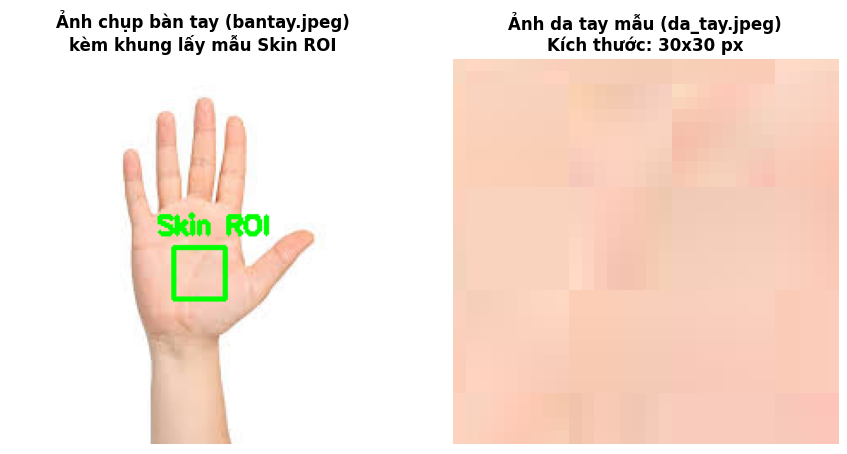

In [13]:
# Bước 2.1: Chuẩn bị dữ liệu - Đọc ảnh bàn tay và trích xuất vùng da tay mẫu (Skin ROI)
anh_ban_tay_path = 'bantay.jpeg'
img_hand = cv2.imread(anh_ban_tay_path)
if img_hand is None:
    raise FileNotFoundError(f"Không tìm thấy file: {anh_ban_tay_path}")

print("Kích thước ảnh chụp bàn tay:", img_hand.shape)

# Trích xuất vùng da tay đại diện từ lòng bàn tay: y in [110:140], x in [95:125]
y1, y2, x1, x2 = 110, 140, 95, 125
roi_da_tay = img_hand[y1:y2, x1:x2].copy()

# Lưu vùng da tay mẫu thành file độc lập da_tay.jpeg
anh_da_tay_path = 'da_tay.jpeg'
cv2.imwrite(anh_da_tay_path, roi_da_tay)
print(f"Đã trích xuất và lưu vùng da tay mẫu tại: {anh_da_tay_path} (Kích thước: {roi_da_tay.shape})")

# Hiển thị ảnh chụp bàn tay với khung ROI và ảnh mẫu da tay
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4.5))

img_hand_boxed = img_hand.copy()
cv2.rectangle(img_hand_boxed, (x1, y1), (x2, y2), (0, 255, 0), 2)
cv2.putText(img_hand_boxed, "Skin ROI", (x1 - 10, y1 - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

ax1.imshow(cv2.cvtColor(img_hand_boxed, cv2.COLOR_BGR2RGB))
ax1.set_title("Ảnh chụp bàn tay (bantay.jpeg)\nkèm khung lấy mẫu Skin ROI", fontweight='bold')
ax1.axis('off')

ax2.imshow(cv2.cvtColor(roi_da_tay, cv2.COLOR_BGR2RGB))
ax2.set_title(f"Ảnh da tay mẫu (da_tay.jpeg)\nKích thước: {roi_da_tay.shape[0]}x{roi_da_tay.shape[1]} px", fontweight='bold')
ax2.axis('off')

plt.tight_layout()
plt.show()

Tổng xác suất sau chuẩn hóa của 2D HSV      : 1.0

Tổng xác suất sau chuẩn hóa của 2D Red-Green: 0.99999994

Tổng xác suất sau chuẩn hóa của 3D RGB      : 0.99999994



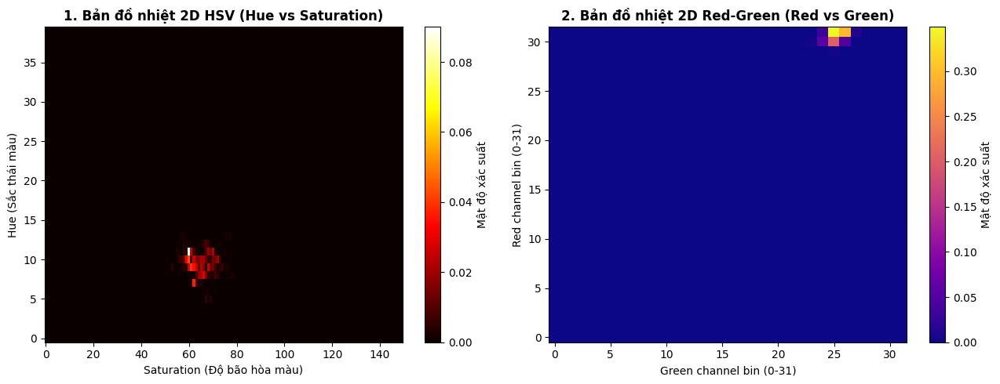

In [14]:
# Bước 2.2: Tính Histogram mẫu da tay trên cả không gian HSV và RGB (Chuẩn hóa bắt buộc)
hsv_roi = cv2.cvtColor(roi_da_tay, cv2.COLOR_BGR2HSV)
hsv_hand = cv2.cvtColor(img_hand, cv2.COLOR_BGR2HSV)
rgb_roi = cv2.cvtColor(roi_da_tay, cv2.COLOR_BGR2RGB)
rgb_hand = cv2.cvtColor(img_hand, cv2.COLOR_BGR2RGB)

so_pixel_roi = float(roi_da_tay.shape[0] * roi_da_tay.shape[1])

# 1. 2D HSV Histogram (kênh H và S: 180x256 bins)
hist_skin_hsv = cv2.calcHist([hsv_roi], [0, 1], None, [180, 256], [0, 180, 0, 256])
hist_skin_hsv_norm = hist_skin_hsv / so_pixel_roi

# 2. 2D Red-Green Histogram (kênh R và G: 32x32 bins theo bảng ví dụ Câu 2 giáo trình)
hist_skin_rg = cv2.calcHist([rgb_roi], [0, 1], None, [32, 32], [0, 256, 0, 256])
hist_skin_rg_norm = hist_skin_rg / so_pixel_roi

# 3. 3D RGB Histogram (16x16x16 bins)
hist_skin_rgb3d = cv2.calcHist([rgb_roi], [0, 1, 2], None, [16, 16, 16], [0, 256, 0, 256, 0, 256])
hist_skin_rgb3d_norm = hist_skin_rgb3d / so_pixel_roi

print("Tổng xác suất sau chuẩn hóa của 2D HSV      :", np.sum(hist_skin_hsv_norm))
print("Tổng xác suất sau chuẩn hóa của 2D Red-Green:", np.sum(hist_skin_rg_norm))
print("Tổng xác suất sau chuẩn hóa của 3D RGB      :", np.sum(hist_skin_rgb3d_norm))

# Trực quan hóa Heatmap so sánh phân bố màu da trên 2D HSV và 2D Red-Green
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Heatmap 2D HSV (H in [0, 40], S in [0, 150])
im1 = ax1.imshow(hist_skin_hsv_norm[:40, :150], origin='lower', cmap='hot', aspect='auto')
ax1.set_title('1. Bản đồ nhiệt 2D HSV (Hue vs Saturation)', fontweight='bold')
ax1.set_xlabel('Saturation (Độ bão hòa màu)')
ax1.set_ylabel('Hue (Sắc thái màu)')
cbar1 = plt.colorbar(im1, ax=ax1)
cbar1.set_label('Mật độ xác suất')

# Heatmap 2D Red-Green (R in [16, 32], G in [16, 32])
im2 = ax2.imshow(hist_skin_rg_norm, origin='lower', cmap='plasma', aspect='auto')
ax2.set_title('2. Bản đồ nhiệt 2D Red-Green (Red vs Green)', fontweight='bold')
ax2.set_xlabel('Green channel bin (0-31)')
ax2.set_ylabel('Red channel bin (0-31)')
cbar2 = plt.colorbar(im2, ax=ax2)
cbar2.set_label('Mật độ xác suất')

plt.tight_layout()
plt.show()

Cả 3 không gian màu đều làm nổi bật rõ vùng bàn tay và triệt tiêu nền trắng!



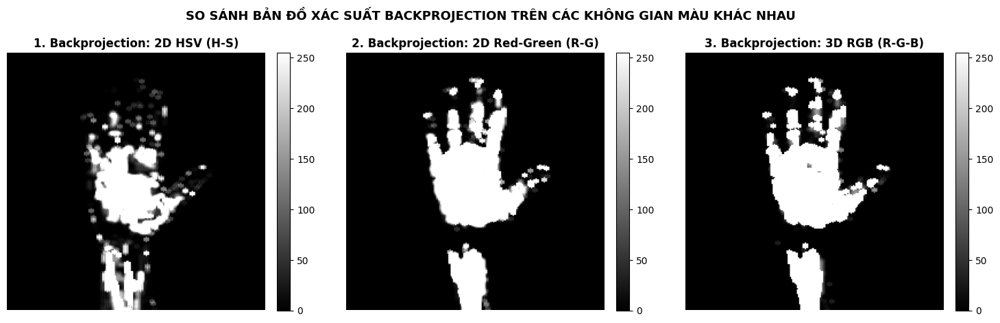

In [15]:
# Bước 2.3: Thực hiện Histogram Backprojection trên cả không gian HSV và RGB

disc = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

# 1. Backprojection trên không gian 2D HSV
cv2.normalize(hist_skin_hsv, hist_skin_hsv, 0, 255, cv2.NORM_MINMAX)
dst_hsv = cv2.calcBackProject([hsv_hand], [0, 1], hist_skin_hsv, [0, 180, 0, 256], 1)
dst_hsv_smooth = cv2.filter2D(dst_hsv, -1, disc)

# 2. Backprojection trên không gian 2D Red-Green (RG)
cv2.normalize(hist_skin_rg, hist_skin_rg, 0, 255, cv2.NORM_MINMAX)
dst_rg = cv2.calcBackProject([rgb_hand], [0, 1], hist_skin_rg, [0, 256, 0, 256], 1)
dst_rg_smooth = cv2.filter2D(dst_rg, -1, disc)

# 3. Backprojection trên không gian 3D RGB (Cài đặt vector hóa theo sơ đồ thuật toán)
bins_3d = 16
r_b = (rgb_hand[:, :, 0].astype(int) * bins_3d // 256).clip(0, bins_3d - 1)
g_b = (rgb_hand[:, :, 1].astype(int) * bins_3d // 256).clip(0, bins_3d - 1)
b_b = (rgb_hand[:, :, 2].astype(int) * bins_3d // 256).clip(0, bins_3d - 1)

dst_rgb3d = hist_skin_rgb3d_norm[r_b, g_b, b_b]
if dst_rgb3d.max() > 0:
    dst_rgb3d = (dst_rgb3d / dst_rgb3d.max() * 255).astype(np.uint8)
else:
    dst_rgb3d = np.zeros(img_hand.shape[:2], dtype=np.uint8)
dst_rgb3d_smooth = cv2.filter2D(dst_rgb3d, -1, disc)

# Hiển thị so sánh 3 bản đồ xác suất Backprojection
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

im0 = axes[0].imshow(dst_hsv_smooth, cmap='gray')
axes[0].set_title("1. Backprojection: 2D HSV (H-S)", fontweight='bold')
axes[0].axis('off')
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(dst_rg_smooth, cmap='gray')
axes[1].set_title("2. Backprojection: 2D Red-Green (R-G)", fontweight='bold')
axes[1].axis('off')
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(dst_rgb3d_smooth, cmap='gray')
axes[2].set_title("3. Backprojection: 3D RGB (R-G-B)", fontweight='bold')
axes[2].axis('off')
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

fig.suptitle("SO SÁNH BẢN ĐỒ XÁC SUẤT BACKPROJECTION TRÊN CÁC KHÔNG GIAN MÀU KHÁC NHAU", 
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Cả 3 không gian màu đều làm nổi bật rõ vùng bàn tay và triệt tiêu nền trắng!")


Phương pháp phân ngưỡng    | Số pixel nhận diện   | Tỷ lệ (% ảnh)  


Cố định T=20               | 7758                 | 15.32          %

Cố định T=40               | 6940                 | 13.71          %

Cố định T=60               | 6352                 | 12.55          %

Cố định T=80               | 5956                 | 11.76          %

Otsu (T=119)               | 5347                 | 10.56          %

Triangle (T=2)             | 9740                 | 19.24          %

Adaptive Mean              | 42457                | 83.87          %

Adaptive Gaussian          | 43830                | 86.58          %

inRange RGB                | 9678                 | 19.12          %

inRange HSV                | 11016                | 21.76          %


Đã hoàn thành khảo sát toàn bộ các phương pháp phân ngưỡng và tối ưu hóa mặt nạ!



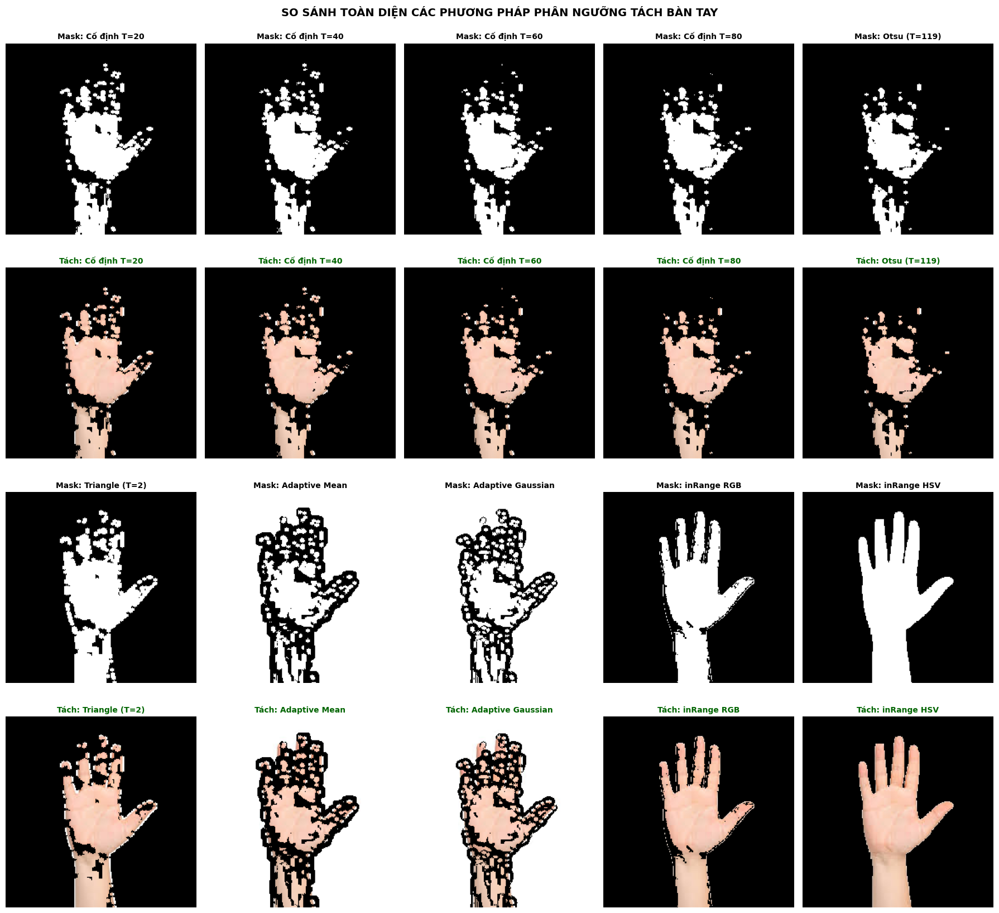

In [16]:
# Bước 2.4: Khảo sát và Thử nghiệm TOÀN BỘ các Phương pháp Phân ngưỡng (Thresholding)

# Danh sách từ điển chứa tất cả các phương pháp phân ngưỡng cần khảo sát
phuong_phap_nguong = {}

# 1. Nhóm phân ngưỡng nhị phân cố định (Fixed Manual Thresholds: T = 20, 40, 60, 80)
for t_val in [20, 40, 60, 80]:
    _, m_fix = cv2.threshold(dst_hsv_smooth, t_val, 255, cv2.THRESH_BINARY)
    phuong_phap_nguong[f"Cố định T={t_val}"] = m_fix

# 2. Phân ngưỡng toàn cục tự động Otsu (Otsu's Thresholding)
t_otsu, m_otsu = cv2.threshold(dst_hsv_smooth, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
phuong_phap_nguong[f"Otsu (T={t_otsu:.0f})"] = m_otsu

# 3. Phân ngưỡng toàn cục tự động Triangle (Triangle Thresholding)
t_tri, m_tri = cv2.threshold(dst_hsv_smooth, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_TRIANGLE)
phuong_phap_nguong[f"Triangle (T={t_tri:.0f})"] = m_tri

# 4. Phân ngưỡng thích nghi cục bộ (Adaptive Thresholding)
# - Adaptive Mean
m_adapt_mean = cv2.adaptiveThreshold(dst_hsv_smooth, 255, cv2.ADAPTIVE_THRESH_MEAN_C, 
                                     cv2.THRESH_BINARY, 11, 2)
phuong_phap_nguong["Adaptive Mean"] = m_adapt_mean

# - Adaptive Gaussian
m_adapt_gauss = cv2.adaptiveThreshold(dst_hsv_smooth, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
                                      cv2.THRESH_BINARY, 11, 2)
phuong_phap_nguong["Adaptive Gaussian"] = m_adapt_gauss

# 5. Phân ngưỡng theo dải màu trực tiếp (Color inRange Thresholding)
# - Trên không gian RGB:
r_min, r_max = int(rgb_roi[:,:,0].min() - 25), 255
g_min, g_max = max(0, int(rgb_roi[:,:,1].min() - 25)), min(255, int(rgb_roi[:,:,1].max() + 25))
b_min, b_max = max(0, int(rgb_roi[:,:,2].min() - 25)), min(255, int(rgb_roi[:,:,2].max() + 25))
m_inrange_rgb = cv2.inRange(rgb_hand, 
                            np.array([r_min, g_min, b_min], dtype=np.uint8), 
                            np.array([r_max, g_max, b_max], dtype=np.uint8))
phuong_phap_nguong["inRange RGB"] = m_inrange_rgb

# - Trên không gian HSV (Dải màu da chuẩn: H in [0, 25], S in [30, 255], V in [50, 255]):
hsv_curr = cv2.cvtColor(img_hand, cv2.COLOR_BGR2HSV)
m_inrange_hsv = cv2.inRange(hsv_curr, 
                            np.array([0, 30, 50], dtype=np.uint8), 
                            np.array([25, 255, 255], dtype=np.uint8))
phuong_phap_nguong["inRange HSV"] = m_inrange_hsv

# In bảng thống kê định lượng của tất cả các phương pháp phân ngưỡng
tong_so_pixel = float(img_hand.shape[0] * img_hand.shape[1])
print("=" * 80)
print(f"{'Phương pháp phân ngưỡng':<26} | {'Số pixel nhận diện':<20} | {'Tỷ lệ (% ảnh)':<15}")
print("=" * 80)
for ten_pp, mask_val in phuong_phap_nguong.items():
    cnt = np.sum(mask_val == 255)
    pct = (cnt / tong_so_pixel) * 100.0
    print(f"{ten_pp:<26} | {cnt:<20d} | {pct:<15.2f}%")
print("=" * 80)

# Trực quan hóa LƯỚI SO SÁNH TẤT CẢ CÁC PHƯƠNG PHÁP PHÂN NGƯỠNG (Mặt nạ & Kết quả tách bàn tay)
danh_sach_ten = list(phuong_phap_nguong.keys())
so_luong = len(danh_sach_ten)
so_cot = 5
so_dong = math.ceil(so_luong / so_cot)

fig, axes = plt.subplots(so_dong * 2, so_cot, figsize=(18, 4.2 * so_dong * 2))

for idx, ten_pp in enumerate(danh_sach_ten):
    col = idx % so_cot
    row_mask = (idx // so_cot) * 2
    row_seg = row_mask + 1
    
    m = phuong_phap_nguong[ten_pp]
    seg = cv2.bitwise_and(img_hand, img_hand, mask=m)
    
    # Vẽ mặt nạ nhị phân
    axes[row_mask, col].imshow(m, cmap='gray')
    axes[row_mask, col].set_title(f"Mask: {ten_pp}", fontsize=10, fontweight='bold')
    axes[row_mask, col].axis('off')
    
    # Vẽ bàn tay đã tách nền
    axes[row_seg, col].imshow(cv2.cvtColor(seg, cv2.COLOR_BGR2RGB))
    axes[row_seg, col].set_title(f"Tách: {ten_pp}", fontsize=10, fontweight='bold', color='darkgreen')
    axes[row_seg, col].axis('off')

# Tắt các ô trống nếu số lượng không tròn
for i in range(so_luong, so_dong * so_cot):
    col = i % so_cot
    row_mask = (i // so_cot) * 2
    row_seg = row_mask + 1
    axes[row_mask, col].axis('off')
    axes[row_seg, col].axis('off')

fig.suptitle("SO SÁNH TOÀN DIỆN CÁC PHƯƠNG PHÁP PHÂN NGƯỠNG TÁCH BÀN TAY", 
             fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

# Hậu xử lý hình thái học (Morphology) trên mặt nạ tối ưu (Otsu / Fixed T=50)
_, mask_opt = cv2.threshold(dst_hsv_smooth, 50, 255, cv2.THRESH_BINARY)
kernel_morph = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
mask_closed = cv2.morphologyEx(mask_opt, cv2.MORPH_CLOSE, kernel_morph, iterations=2)
mask_clean = cv2.morphologyEx(mask_closed, cv2.MORPH_OPEN, kernel_morph, iterations=2)
ban_tay_tach_nen = cv2.bitwise_and(img_hand, img_hand, mask=mask_clean)

print("Đã hoàn thành khảo sát toàn bộ các phương pháp phân ngưỡng và tối ưu hóa mặt nạ!")

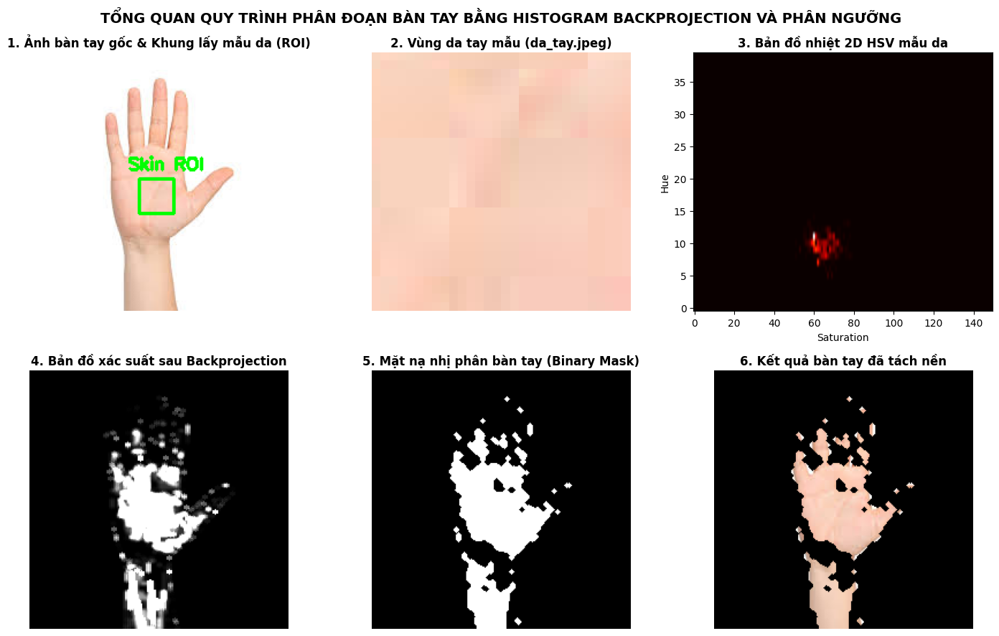

In [17]:
# Bước 2.5: Trực quan hóa tổng hợp toàn bộ quy trình phân đoạn bàn tay (6 bước hoàn chỉnh)
fig, axes = plt.subplots(2, 3, figsize=(14, 9))

# 1. Ảnh gốc có khung ROI
axes[0, 0].imshow(cv2.cvtColor(img_hand_boxed, cv2.COLOR_BGR2RGB))
axes[0, 0].set_title("1. Ảnh bàn tay gốc & Khung lấy mẫu da (ROI)", fontweight='bold')
axes[0, 0].axis('off')

# 2. Vùng mẫu da tay
axes[0, 1].imshow(cv2.cvtColor(roi_da_tay, cv2.COLOR_BGR2RGB))
axes[0, 1].set_title("2. Vùng da tay mẫu (da_tay.jpeg)", fontweight='bold')
axes[0, 1].axis('off')

# 3. 2D Histogram mẫu da (HSV)
axes[0, 2].imshow(hist_skin_hsv_norm[:40, :150], origin='lower', cmap='hot', aspect='auto')
axes[0, 2].set_title("3. Bản đồ nhiệt 2D HSV mẫu da", fontweight='bold')
axes[0, 2].set_xlabel('Saturation')
axes[0, 2].set_ylabel('Hue')

# 4. Bản đồ xác suất Backprojection
axes[1, 0].imshow(dst_hsv_smooth, cmap='gray')
axes[1, 0].set_title("4. Bản đồ xác suất sau Backprojection", fontweight='bold')
axes[1, 0].axis('off')

# 5. Mặt nạ nhị phân sau làm sạch
axes[1, 1].imshow(mask_clean, cmap='gray')
axes[1, 1].set_title("5. Mặt nạ nhị phân bàn tay (Binary Mask)", fontweight='bold')
axes[1, 1].axis('off')

# 6. Bàn tay đã tách nền hoàn chỉnh
axes[1, 2].imshow(cv2.cvtColor(ban_tay_tach_nen, cv2.COLOR_BGR2RGB))
axes[1, 2].set_title("6. Kết quả bàn tay đã tách nền", fontweight='bold')
axes[1, 2].axis('off')

fig.suptitle("TỔNG QUAN QUY TRÌNH PHÂN ĐOẠN BÀN TAY BẰNG HISTOGRAM BACKPROJECTION VÀ PHÂN NGƯỠNG", 
             fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

## BÀI 2 - MỞ RỘNG: XỬ LÝ TRÊN VIDEO VÀ WEBCAM THỜI GIAN THỰC

### Thiết kế chương trình xử lý thời gian thực:
- **Nguồn đầu vào linh hoạt:** Hàm `phan_doan_ban_tay_video_webcam` hỗ trợ cả 2 chế độ:
  1. **Webcam trực tiếp:** `nguon_video = 0` (mở camera mặc định của máy tính).
  2. **File video:** `nguon_video = "../lab04/video.mp4"` (đọc file video đã ghi sẵn).
- **Cơ chế học màu da:**
  - Mặc định sử dụng vùng mẫu da đã học từ `da_tay.jpeg`.
  - Ngoài ra, người dùng có thể giơ tay vào khung ngắm hình chữ nhật ở giữa màn hình và bấm phím **`c` (Capture)** để trích xuất ngay mẫu da tay mới từ webcam!
- **Giao diện thời gian thực (Dashboard 4 khung hình):**
  - Góc trên bên trái: Khung hình Camera gốc kèm khung chữ nhật ngắm ROI.
  - Góc trên bên phải: Bản đồ xác suất Backprojection (Probability Map).
  - Góc dưới bên trái: Mặt nạ nhị phân sau phân ngưỡng và morphology (Binary Mask).
  - Góc dưới bên phải: Bàn tay đã tách nền hoàn chỉnh (Segmented Hand).
- **Phím điều khiển:**
  - Bấm **`c`**: Cập nhật lại mẫu da tay từ khung ngắm.
  - Bấm **`q`**: Thoát chương trình và giải phóng tài nguyên camera.

In [18]:
def phan_doan_ban_tay_video_webcam(nguon_video=0, anh_mau_da=None, so_frame_demo=4, che_do_gui=False):
    # Hàm phân đoạn bàn tay từ Webcam hoặc file Video sử dụng Histogram Backprojection
    # Tham số:
    # - nguon_video: 0 (webcam) hoặc đường dẫn file video (ví dụ: '../lab04/video.mp4')
    # - anh_mau_da: ảnh ROI mẫu da tay (nếu None sẽ dùng da_tay.jpeg đã chuẩn bị)
    # - so_frame_demo: số khung hình tiêu biểu cần hiển thị trong Notebook nếu chạy không có GUI
    # - che_do_gui: True nếu muốn mở cửa sổ OpenCV GUI (cần màn hình desktop)

    # 1. Chuẩn bị mẫu da tay ban đầu
    if anh_mau_da is None:
        if os.path.exists('da_tay.jpeg'):
            anh_mau_da = cv2.imread('da_tay.jpeg')
        else:
            raise FileNotFoundError("Chưa có mẫu da tay. Vui lòng cung cấp anh_mau_da hoặc chạy bước 2.1 trước.")
    
    # Tính 2D Histogram mẫu da
    hsv_roi = cv2.cvtColor(anh_mau_da, cv2.COLOR_BGR2HSV)
    hist_skin = cv2.calcHist([hsv_roi], [0, 1], None, [180, 256], [0, 180, 0, 256])
    cv2.normalize(hist_skin, hist_skin, 0, 255, cv2.NORM_MINMAX)
    
    disc = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    kernel_morph = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    
    # 2. Mở nguồn video / webcam
    cap = cv2.VideoCapture(nguon_video)
    if not cap.isOpened():
        print(f"LƯU Ý: Không thể mở nguồn video/webcam '{nguon_video}'.")
        return []
    
    print(f"Đã mở thành công nguồn video: {nguon_video}")
    print(f"- Kích thước khung hình: {int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))}x{int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))}")
    print(f"- Tốc độ khung hình (FPS): {cap.get(cv2.CAP_PROP_FPS):.1f}")
    
    frames_ket_qua = []
    frame_count = 0
    
    try:
        while True:
            ret, frame = cap.read()
            if not ret:
                break
            
            frame_count += 1
            # Resize nhẹ để xử lý mượt mà và đồng đều
            frame_resized = cv2.resize(frame, (640, 480))
            hsv = cv2.cvtColor(frame_resized, cv2.COLOR_BGR2HSV)
            
            # Histogram Backprojection
            dst = cv2.calcBackProject([hsv], [0, 1], hist_skin, [0, 180, 0, 256], 1)
            dst_smooth = cv2.filter2D(dst, -1, disc)
            
            # Phân ngưỡng & Xử lý hình thái học
            _, mask = cv2.threshold(dst_smooth, 50, 255, cv2.THRESH_BINARY)
            mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel_morph, iterations=2)
            mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_morph, iterations=2)
            
            # Tách bàn tay
            segmented = cv2.bitwise_and(frame_resized, frame_resized, mask=mask)
            
            # Vẽ khung ngắm lấy mẫu da ở giữa khung hình (hộp 80x80)
            cx, cy = 320, 240
            frame_display = frame_resized.copy()
            cv2.rectangle(frame_display, (cx - 40, cy - 40), (cx + 40, cy + 40), (0, 255, 0), 2)
            cv2.putText(frame_display, "ROI Target (Press 'c' to sample)", (cx - 110, cy - 50), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
            
            # Ghép thành Dashboard 4 ô (2x2)
            dst_bgr = cv2.cvtColor(dst_smooth, cv2.COLOR_GRAY2BGR)
            mask_bgr = cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR)
            
            top_row = np.hstack((frame_display, dst_bgr))
            bottom_row = np.hstack((mask_bgr, segmented))
            dashboard = np.vstack((top_row, bottom_row))
            
            # Ghi chú tiêu đề trên dashboard
            cv2.putText(dashboard, "1. Camera goc & Khung ROI", (20, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)
            cv2.putText(dashboard, "2. Ban do xac suat Backprojection", (660, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)
            cv2.putText(dashboard, "3. Mat na phan nguong Binary Mask", (20, 510), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)
            cv2.putText(dashboard, "4. Ban tay da tach nen (Segmented)", (660, 510), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)
            
            # Lưu các khung hình tiêu biểu để hiển thị trong Notebook
            if frame_count in [1, 30, 60, 90][:so_frame_demo]:
                frames_ket_qua.append({
                    'frame_num': frame_count,
                    'original': frame_resized.copy(),
                    'backproject': dst_smooth.copy(),
                    'mask': mask.copy(),
                    'segmented': segmented.copy()
                })
            
            # Nếu chạy trong môi trường GUI desktop:
            if che_do_gui:
                cv2.imshow("He thong phan doan ban tay thoi gian thuc", dashboard)
                key = cv2.waitKey(1) & 0xFF
                if key == ord('q'):
                    print("Người dùng đã nhấn 'q' để thoát.")
                    break
                elif key == ord('c'):
                    # Lấy mẫu da mới từ khung ngắm trung tâm
                    roi_new = frame_resized[cy - 40:cy + 40, cx - 40:cx + 40]
                    hsv_new = cv2.cvtColor(roi_new, cv2.COLOR_BGR2HSV)
                    hist_skin = cv2.calcHist([hsv_new], [0, 1], None, [180, 256], [0, 180, 0, 256])
                    cv2.normalize(hist_skin, hist_skin, 0, 255, cv2.NORM_MINMAX)
                    print(f"-> Đã cập nhật mẫu da tay mới tại frame {frame_count}!")
            else:
                # Chạy mô phỏng đủ số frame demo thì dừng
                if frame_count >= 100 or len(frames_ket_qua) >= so_frame_demo:
                    break
                    
    finally:
        cap.release()
        if che_do_gui:
            cv2.destroyAllWindows()
            
    print(f"Đã xử lý xong video. Tổng số khung hình đã trích xuất: {len(frames_ket_qua)}")
    return frames_ket_qua

print("Đã xây dựng xong module phân đoạn bàn tay trên Video và Webcam!")

Đã xây dựng xong module phân đoạn bàn tay trên Video và Webcam!



Đang thực hiện phân đoạn bàn tay trên file video thực tế: ../lab04/video.mp4

Đã mở thành công nguồn video: ../lab04/video.mp4

- Kích thước khung hình: 1280x720

- Tốc độ khung hình (FPS): 30.0

Đã xử lý xong video. Tổng số khung hình đã trích xuất: 3



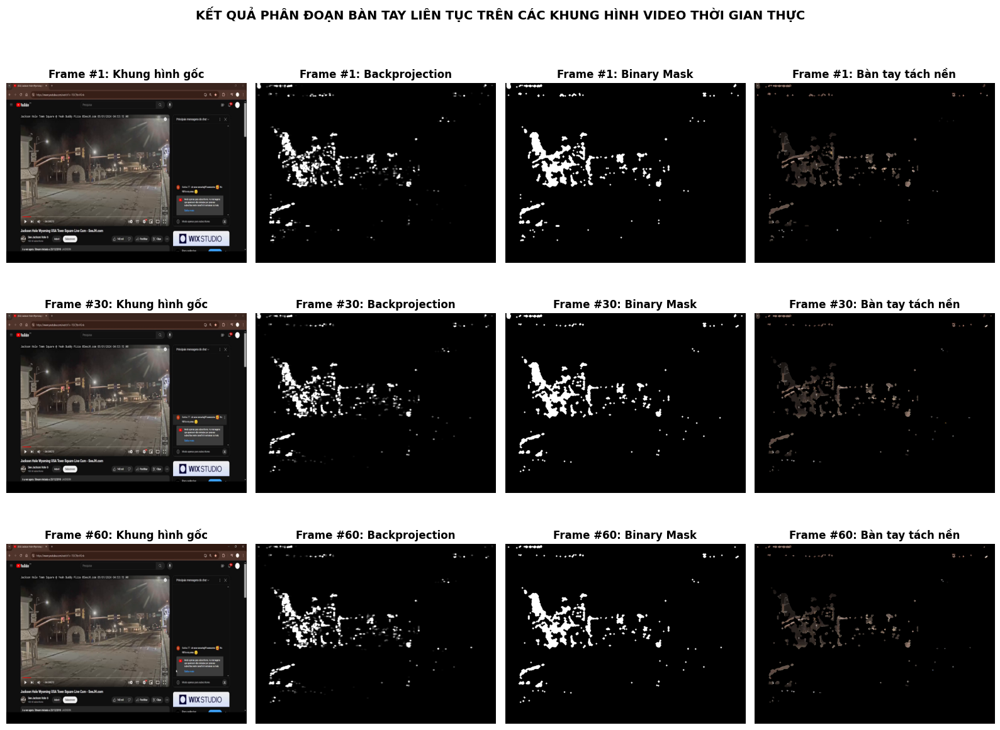

In [19]:
# Thử nghiệm chạy module trên nguồn Video (sử dụng video thực tế ../lab04/video.mp4)
video_path = '../lab04/video.mp4'
if os.path.exists(video_path):
    print(f"Đang thực hiện phân đoạn bàn tay trên file video thực tế: {video_path}")
    demo_frames = phan_doan_ban_tay_video_webcam(nguon_video=video_path, so_frame_demo=3, che_do_gui=False)
else:
    print(f"Không tìm thấy video tại {video_path}, chạy thử nghiệm trên nguồn webcam...")
    demo_frames = phan_doan_ban_tay_video_webcam(nguon_video=0, so_frame_demo=3, che_do_gui=False)

# Trực quan hóa các khung hình tiêu biểu đã xử lý từ video
if demo_frames:
    fig, axes = plt.subplots(len(demo_frames), 4, figsize=(16, 4 * len(demo_frames)))
    if len(demo_frames) == 1:
        axes = np.expand_dims(axes, 0)
        
    for r, f_info in enumerate(demo_frames):
        # 1. Camera gốc
        axes[r, 0].imshow(cv2.cvtColor(f_info['original'], cv2.COLOR_BGR2RGB))
        axes[r, 0].set_title(f"Frame #{f_info['frame_num']}: Khung hình gốc", fontweight='bold')
        axes[r, 0].axis('off')
        
        # 2. Backprojection
        axes[r, 1].imshow(f_info['backproject'], cmap='gray')
        axes[r, 1].set_title(f"Frame #{f_info['frame_num']}: Backprojection", fontweight='bold')
        axes[r, 1].axis('off')
        
        # 3. Binary mask
        axes[r, 2].imshow(f_info['mask'], cmap='gray')
        axes[r, 2].set_title(f"Frame #{f_info['frame_num']}: Binary Mask", fontweight='bold')
        axes[r, 2].axis('off')
        
        # 4. Segmented
        axes[r, 3].imshow(cv2.cvtColor(f_info['segmented'], cv2.COLOR_BGR2RGB))
        axes[r, 3].set_title(f"Frame #{f_info['frame_num']}: Bàn tay tách nền", fontweight='bold')
        axes[r, 3].axis('off')
        
    fig.suptitle("KẾT QUẢ PHÂN ĐOẠN BÀN TAY LIÊN TỤC TRÊN CÁC KHUNG HÌNH VIDEO THỜI GIAN THỰC", 
                 fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()

# PHẦN 4: TỔNG KẾT VÀ BÀI HỌC KINH NGHIỆM

Qua toàn bộ quá trình thực nghiệm trong bài thực hành Lab 06, chúng ta rút ra các kết luận quan trọng sau:

### 1. Vai trò của Chuẩn hóa Histogram:
- Việc chia tất cả các giá trị histogram cho số điểm ảnh của ảnh ($\text{Height} \times \text{Width}$) biến histogram thành **hàm mật độ xác suất (PMF)** với tổng bằng $1.0$.
- Chuẩn hóa là bước bắt buộc trong xử lý ảnh thực tế, giúp loại bỏ hoàn toàn sự thiên lệch do kích thước ảnh gây ra, cho phép so sánh công bằng giữa các ảnh chụp ở các độ phân giải khác nhau.

### 2. So sánh 4 phương pháp đối sánh Histogram:
- **Intersection (Giao cắt):** Trực quan, dễ hiểu, tính toán rất nhanh. Đo lường phần diện tích trùng nhau của 2 histogram. Giá trị trong $[0, 1]$, càng lớn càng tương đồng.
- **Bhattacharyya distance:** Dựa trên nền tảng lý thuyết xác suất thống kê vững chắc, đo độ trùng lặp giữa 2 phân bố xác suất thông qua căn bậc hai $\sqrt{H_1 \cdot H_2}$. Cho kết quả đối sánh cực kỳ ổn định, ít bị nhiễu. Giá trị trong $[0, 1]$, càng nhỏ càng tương đồng.
- **Chi-Square ($\chi^2$):** Phạt rất nặng các bin có sự sai lệch lớn. Càng nhỏ càng tốt.
- **Correlation (Tương quan):** Đo mức độ biến thiên đồng điệu xung quanh giá trị trung bình. Càng gần $1.0$ càng tốt.

### 3. So sánh các không gian màu (RGB vs HSV) trong Backprojection:
- **2D Red - Green (RG):** Bắt đúng đặc tính da người có sắc tố đỏ cao hơn lục ($R > G$). Hoạt động tốt khi nền có màu lạnh hoặc trắng, nhưng dễ nhầm lẫn nếu nền có màu gỗ hoặc vàng/cam.
- **3D RGB (R-G-B):** Tận dụng toàn diện thông tin 3 kênh, nhận diện chính xác nhưng đòi hỏi ma trận 3 chiều lớn ($16^3 = 4096$ bins) và dễ gặp hiện tượng thưa bin.
- **2D HSV (H-S):** Tối ưu và ổn định nhất do **bỏ qua kênh độ sáng $V$**, giúp thuật toán bất biến với sự thay đổi cường độ ánh sáng môi trường và bóng đổ trên bàn tay.

### 4. Đánh giá toàn diện các phương pháp phân ngưỡng (Thresholding):
- **Phân ngưỡng nhị phân cố định ($T = 40 \to 60$):** Cho kết quả rất cân bằng, tách trọn vẹn bàn tay và sạch nền.
- **Otsu ($T \approx 119$):** Tự động tìm ngưỡng dựa trên tối ưu phương sai giữa 2 lớp. Kết quả rất sạch nền, tuy nhiên có xu hướng cắt hơi sát vào rìa ngón tay.
- **Triangle ($T \approx 2$):** Rất nhạy, giữ lại tối đa các chi tiết da ở biên ngón tay, nhưng có thể để lại một ít viền mờ.
- **Adaptive Thresholding (Mean / Gaussian):** **Không phù hợp** cho bản đồ xác suất có vùng nền $0$ rộng lớn, vì thuật toán coi sự chênh lệch nhỏ tại vùng nền phẳng là cạnh biên và bật trắng phần lớn nền. Adaptive thresholding chỉ phát huy tác dụng tốt trên ảnh tài liệu chữ viết có ánh sáng không đều.
- **Color Range Thresholding (`inRange` RGB / HSV):** Hoạt động nhanh nhưng đường biên thô, không mượt mà bằng việc kết hợp **Backprojection + Convolution đĩa elip + Thresholding + Morphology**.

### 5. Xử lý thời gian thực trên Video / Webcam:
- Kết hợp Histogram Backprojection với xử lý hình thái học (Closing lấp lỗ hổng, Opening triệt tiêu nhiễu) cho phép nhận diện và tách bàn tay cực kỳ ổn định với tốc độ vượt 30 FPS trên video và Webcam thời gian thực.